# Práctica 4. Detección y seguimiento de personas, vehículos y matrículas

En esta práctica se desarrolla un sistema de **detección y seguimiento de objetos** que aparecen en un vídeo de prueba, identificando  personas, vehículos y matrículas mediante modelos de visión por computador.

Además, se implementan mecanismos de **anonimización de personas y matrículas** mediante el pixelado de la mismas.

Asimismo, se realiza un **recuento del flujo de objetos**, registrando además aquellos que entran y salen de la escena e incluso identificando el lado por el que se produce cada entrada o salida. Para ello, se utilizan técnicas de seguimiento que permiten mantener la identidad de los objetos a lo largo de los diferentes fotogramas del vídeo.

Los resultados son exportados a un vídeo final ya procesado y a ficheros CSV donde se recogen los datos solicitados por la tarea de la práctica.

Principalmente, se ha utilizado para la implementación la librería **OpenCV y modelos YOLO**.

### Paquetes necesarios
- Se utilizan OpenCV y Ultralytics; ByteTrack requiere `lap`. 
- El OCR usa `TextRecognition` de PaddleOCR 3.7.0 y PaddlePaddle GPU 3.2.2, instalado para Windows de 64 bits y Python 3.9 con CUDA 11.8.
- PyTorch y PaddlePaddle mantienen distribuciones CUDA independientes.

* Comandos de referencia para el entorno `VC_P4`:

```powershell
conda activate VC_P4
python -m pip uninstall -y paddlepaddle
python -m pip install "paddlepaddle-gpu==3.2.2" -i https://www.paddlepaddle.org.cn/packages/stable/cu118/
python -m pip install "paddleocr==3.7.0"
```

- La configuración `ocr_device = "gpu:0"` selecciona la primera GPU para Paddle. Para utilizar CPU con la distribución GPU instalada puede cambiarse a `"cpu"`. 


In [1]:
import os
import cv2
import math
import csv
import json
import time
import re
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import torch
from ultralytics import YOLO

### Configuración
- El modelo general que hemos usado (YOLO11n) reconoce personas y vehículos (`yolo11n.pt`).

- Los pesos del modelo entrenado con nuestro conjunto de matrículas (`best.pt`) es el detector de una sola clase (`plate`) entrenado previamente.

- Los conteos utilizan identidades estimadas con una recuperación conservadora de vehículos estacionados tras ocultaciones; los errores de identidad todavía pueden producir sobreconteo o subconteo.

In [2]:
filename = "video_test.mp4"
pesos_general = "yolo11n.pt"
pesos_matriculas = "results/model_yolo11n_detect_plates/weights/best.pt"
carpeta_salida = Path("results/plates_secuencial")
carpeta_dataset = Path("dataset_plates")
classes = [0, 1, 2, 3, 5, 7]  # Persona, bicicleta, coche, moto, autobús y camión.
conf_objeto = 0.25
conf_matricula = 0.25
conf_anonimizar = 0.15
imgsz = 640
device = 0 if torch.cuda.is_available() else "cpu"
ocr_device = "gpu:0"  # Motor Paddle independiente del CUDA de PyTorch.
OCR_TAMANO_LOTE = 16  # Máximo de imágenes de línea por inferencia.
OCR_CADA_N_FOTOGRAMAS = 1  # 1: todos; para reducir las lecturas OCR.
OCR_VENTANA_LECTURAS = 5  # Entre 5 y 10 lecturas válidas por vehículo.
OCR_MARGEN = 0.08  # Margen por lado, limitado a la caja del vehículo.
OCR_LETRA_PARA_UNO = "L"  # Posible alternativa: "T"; el formato no resuelve esta ambigüedad. Hemos optado por "L" por "1" si se detecta en la parte numérica de la matrícula.
ESCALA_PANELES_FLUJO = 0.75  # Tamaño paneles de recuento.
ESPERA_SALIDA_S = 0.2  # Tiempo sin detección para confirmar una salida estimada.
MOSTRAR = True  # Ver anotaciones y flujo durante el procesamiento.
GENERAR_VIDEO_ANONIMIZADO = True  # True: para generar después del anotado.
USAR_OCR = True
INICIO_SEGUNDOS = 0  # Para empezar el vídeo en otro momento.
FIN_SEGUNDOS = None  # Por ejemplo: inicio 25 y fin 50.
MAX_FRAMES = None  # Límite adicional desde el inicio elegido; normalmente None.
EVALUAR_YOLO = False
VER_ENTRENAMIENTO = True  # Muestra gráficas de entrenamiento.

# Recuperación de vehículos estacionados tras una ocultación (cámara fija).
MEMORIA_ESTACIONADOS_S = 120.0
TIEMPO_ESTACIONARIO_S = 0.6
IOU_RECUPERAR = 0.55
DISTANCIA_APARIENCIA_MAX = 0.25
VENTANA_REASOCIACION_S = 1.0  # Continuidad espacial ante cambios breves de ID.
TOLERANCIA_REPOSO = 0.12  # Fracción de la diagonal, con un máximo de 12 px a 1080p.
CONTAR_ENTRADAS_INICIALES_EN_BORDE = True  # Entrada inferida si ya toca un lateral al inicio.


### Operaciones auxiliares
- Definimos las funciones `limitar cajas`, `pixelar` y calcular IoU (`iou`). 

- El pixelado reduce una región con `INTER_AREA` y la amplía con `INTER_NEAREST` para lograr un pixelado que anonimice. Se amplían los bordes y se limita el número de celdas para reducir el detalle también en objetos grandes.

In [3]:
def limitar_caja(caja, ancho, alto):
    # Conservamos sólo la parte de la caja que está dentro del fotograma
    x1, y1, x2, y2 = map(int, caja)
    return (
        max(0, min(ancho, x1)),
        max(0, min(alto, y1)),
        max(0, min(ancho, x2)),
        max(0, min(alto, y2)),
    )


def pixelar(img, caja, max_celdas=25, bloque=8):
    alto, ancho = img.shape[:2]
    x1, y1, x2, y2 = caja
    mx, my = max(2, math.ceil((x2 - x1) * 0.08)), max(2, math.ceil((y2 - y1) * 0.08))
    x1, y1, x2, y2 = limitar_caja((x1 - mx, y1 - my, x2 + mx, y2 + my), ancho, alto)
    if x2 <= x1 or y2 <= y1:
        return
    roi = img[y1:y2, x1:x2]
    h, w = roi.shape[:2]
    paso = max(bloque, math.ceil(max(h, w) / max_celdas))
    pequena = cv2.resize(roi, (max(1, w // paso), max(1, h // paso)), interpolation=cv2.INTER_AREA)
    img[y1:y2, x1:x2] = cv2.resize(pequena, (w, h), interpolation=cv2.INTER_NEAREST)


def iou(a, b):
    inter = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

### OCR con PaddleOCR
Se crea una única instancia de `TextRecognition` de PaddleOCR 3.x, con el modelo inglés `en_PP-OCRv5_mobile_rec`, así evitamos la 'Ñ' y todas las vocales con tilde, entre otras. Se realiza exclusivamente reconocimiento sobre recortes de la matrícula.

YOLO localiza la matrícula dentro del vehículo. Se añade un margen configurable `OCR_MARGEN = 0.08` por lado, limitado a la imagen y a la caja del vehículo. Se amplían los recortes pequeños y se conservan las coordenadas originales de detección para el dibujo y el CSV. El OCR recibe exclusivamente este recorte, nunca el coche completo.

En las matrículas de dos filas se busca una separación horizontal central y se reconocen ambas filas en un lote, concatenando primero la superior. Esto admite cuatro números arriba y tres letras abajo, o letras arriba y cuatro números abajo. Si falla, se prueba el recorte completo. Los reintentos utilizan original, contraste CLAHE y binarización Otsu. La separación es heurística y puede fallar con perspectiva, bordes o recortes incompletos.

Se eliminan separadores y se convierten los caracteres a mayúsculas, conservando los ceros iniciales. Las letras no admitidas no se borran sin más. Se preservan primero los candidatos válidos, incluidos los formatos antiguos con prefijo provincial reconocido de una o dos letras, cuatro dígitos y sufijo opcional de hasta dos letras. Para candidatos actuales de ocho caracteres con prefijo `E`, se elimina esa letra antes de aplicar la corrección posicional.

En los cuatro primeros caracteres se sustituyen `O→0`, `I/L→1`, `Z→2`, `B→8`, `S→5` y `G→6`. En las tres posiciones finales se utilizan `0→D`, `1→L`, `2→Z`, `8→B`, `5→S` y `6→G`. `OCR_LETRA_PARA_UNO` permite escoger `T` en lugar de `L`. Estas sustituciones son hipótesis: la forma de la matrícula no demuestra que un `0` sea una `D`, ni distingue entre `L` y `T`. Pueden producir candidatos incorrectos aunque cumplan el patrón.

El resultado para una matrícula actual debe cumplir estrictamente `[0-9]{4}[BCDFGHJKLMNPRSTVWXYZ]{3}`. Esta restricción no se aplica a los formatos antiguos. Cada posición representa una letra individual: `CH` y `LL` son símbolos adicionales del alfabeto los cuales realmente están compuestos por 2 letras. Si ningún intento produce un candidato válido, texto y confianza quedan vacíos.

La confianza exportada procede del reconocedor antes de las correcciones y no es una probabilidad calibrada de acierto del texto corregido. No se consultan las anotaciones del dataset para leer el vídeo. El OCR utiliza la imagen antes del pixelado. Con `USAR_OCR = False`, texto y confianza quedan vacíos.

Se mantiene `enable_mkldnn=False` para evitar el error de conversión de atributos PIR observado en esta instalación Windows. Se debe recrear el lector tras cambiar su configuración. La velocidad real debe medirse en el equipo: eliminar el detector de texto reduce trabajo, pero los reintentos y las placas de dos filas añaden inferencias.
### Frecuencia de reconocimiento
`OCR_CADA_N_FOTOGRAMAS = 3` ejecuta el OCR en los fotogramas procesados 1, 4, 7, etc., contados desde el inicio del tramo. Con `2` se lee en 1, 3, 5, etc.; con `1` se reconoce en todos. Las detecciones de objetos y matrículas, el seguimiento, la exportación CSV y la escritura del vídeo se mantienen en cada fotograma.

Los fotogramas sin OCR no añaden lecturas ni votos, ni reutilizan el consenso como si fuera una lectura nueva. Se conserva el texto consolidado y se dibuja sobre la caja de matrícula actual. `texto_ocr_fotograma` queda vacío y `ocr_ejecutado` vale 0 cuando se omite el reconocimiento; vale 1 cuando se ha intentado, incluso si el resultado es inválido. La ventana sigue conteniendo cinco lecturas válidas, que ahora pueden abarcar más tiempo. El intervalo se registra en `resumen.json`.

La reducción del trabajo OCR puede mejorar la velocidad, pero también puede perder oportunidades de leer matrículas visibles durante poco tiempo. La mejora se debe medir procesando el mismo tramo con la misma configuración y distintos intervalos; no se atribuyen cifras sin medirlas.

### GPU y reconocimiento por lotes
El entorno utiliza PaddlePaddle GPU 3.2.2 para Windows/Python 3.9, con CUDA 11.8, y el lector se configura mediante `ocr_device = "gpu:0"`. Se verifica que Paddle esté compilado con CUDA y detecte una GPU; esta comprobación es independiente de PyTorch. La asignación `auto_growth` permite solicitar memoria según se necesita, compartiendo la GPU con YOLO. El kernel debe reiniciarse después de sustituir PaddlePaddle CPU.

Las matrículas de un mismo fotograma se agrupan en una lista. Cada placa horizontal aporta una imagen; cada placa compacta aporta dos filas ordenadas. `OCR_TAMANO_LOTE = 16` limita las imágenes de línea por llamada, dividiendo grupos mayores en varios lotes. Se reconstruye la correspondencia entre resultados y matrículas incluso si las filas de una placa quedan en lotes distintos. Cada placa aporta como máximo una lectura al voto del fotograma.

Los reintentos solo incluyen placas pendientes: primero la imagen original, después CLAHE y finalmente Otsu. Las placas compactas que fallan con filas separadas se ensayan completas. Las placas ya válidas no vuelven a reconocerse. El procesamiento por lotes no añade espera entre fotogramas y mantiene el OCR cada tres fotogramas y la ventana de cinco lecturas.

La validación se repite antes de admitir votos, conservar un consenso, dibujar o exportar texto. Las lecturas nuevas con formato inválido no sustituyen el último consenso válido. Los formatos antiguos requieren un prefijo provincial reconocido (incluidas las variantes históricas GE, PM y OR); no se admite un prefijo arbitrario de tres letras. Esta validación comprueba los formatos considerados en el ejercicio, sin consultar un registro de vehículos. La caja geométrica puede seguir disponible para la anonimización aunque no se acepte su texto.


In [4]:
reader = None
if USAR_OCR:
    os.environ.setdefault("FLAGS_allocator_strategy", "auto_growth")
    try:
        import paddle
        from paddleocr import TextRecognition
    except ImportError as error:
        raise ImportError(
            "Instala paddlepaddle-gpu y paddleocr 3.x en el kernel VC_P4 y reinícialo. "
            "Consulta la celda de paquetes necesarios."
        ) from error

    if ocr_device.startswith("gpu") and (
        not paddle.is_compiled_with_cuda() or paddle.device.cuda.device_count() < 1
    ):
        raise RuntimeError("Paddle no dispone de CUDA. Revisa paddlepaddle-gpu y reinicia el kernel.")

    # API 3.x: reconocimiento directo, sin detector de texto ni clasificador angular.
    # El nombre del modelo selecciona explícitamente el reconocedor inglés.
    reader = TextRecognition(
        model_name="en_PP-OCRv5_mobile_rec",
        device=ocr_device,
        enable_mkldnn=True,
    )

c:\Users\njhm\anaconda3\envs\VC_P4\lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
c:\Users\njhm\anaconda3\envs\VC_P4\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\njhm\.paddlex\official_models\en_PP-OCRv5_mobile_rec`.


### Detección y seguimiento del vídeo
Se emplean `model.track(img, persist=True)` y el recorrido `for box in boxes`. Para pixelar personas sin ID se conservan sus cajas previas al tracker mediante un callback breve, registrado antes de la primera llamada a `track`. No se ejecuta otra red: se conserva el umbral 0,25 del seguimiento y se guardan las cajas desde 0,15 para anonimizar.

In [5]:
privacy = {"boxes": []}


def guardar_cajas_anonimizar(predictor):
    r = predictor.results[0]
    if r.boxes is None:
        privacy["boxes"] = []
        return
    # Clase 0: personas. La carrocería de los vehículos no se pixela.
    personas = (r.boxes.cls == 0) & (r.boxes.conf >= conf_anonimizar)
    privacy["boxes"] = r.boxes.xyxy[personas].cpu().tolist()
    predictor.results[0] = r[r.boxes.conf >= conf_objeto]

## Bucle de procesamiento
Cada fotograma se detecta, se representa y se escribe. Se conservan historial de centros y votos de clase por ID; el recuento de flujo utiliza la clase mayoritaria de las primeras 30 observaciones. Esta ventana inicial evita que clasificaciones tardías, con el objeto más pequeño o parcialmente oculto, cambien una moto ya reconocida por un coche. Los votos completos se conservan para el seguimiento. Las matrículas se buscan exclusivamente dentro de las cajas de los vehículos detectados y quedan asociadas al vehículo cuyo recorte las originó. El OCR se aplica después a cada recorte de matrícula.

El CSV contiene una fila por objeto y fotograma, o por asociación si hay varias matrículas. Las confianzas se denominan `confianza` y `confianza_matricula`; los datos ausentes se dejan vacíos. Los fotogramas comienzan en 1.

`video_anotado.mp4` muestra las detecciones sin estelas de seguimiento. Las cajas de las matrículas son rosas; su texto validado sigue en amarillo sobre fondo negro. `video_anonimizado.mp4` se crea en una segunda fase opcional y pixela personas y matrículas, sin etiquetas OCR. `GENERAR_VIDEO_ANONIMIZADO = False` genera únicamente el anotado; con `True` se guardan primero las cajas y después se vuelve a leer el tramo original para escribir el anonimizado, reutilizando las detecciones sin ejecutar de nuevo YOLO ni OCR. La carrocería de los vehículos permanece visible. Se conservan las últimas cajas durante 0,4 segundos para pérdidas breves. Se mantienen resolución y FPS, sin pista de audio. El progreso muestra FPS y tiempo restante sin saltar imágenes. Para repetir el procesamiento se vuelve a ejecutar esta celda: carga modelos nuevos y reinicia el tracking.

### 1. Detectar personas y vehículos
Esta función ejecuta la red general y ByteTrack, recorre sus cajas y devuelve una lista con posición, confianza, clase e ID.

In [6]:
def detectar_objetos(img, model, width, height):
    conf = min(conf_objeto, conf_anonimizar) if GENERAR_VIDEO_ANONIMIZADO else conf_objeto
    results = model.track(
        img,
        persist=True,
        classes=classes,
        conf=conf,
        tracker="bytetrack.yaml",
        imgsz=imgsz,
        device=device,
        verbose=False,
    )
    objetos = []
    for r in results:
        boxes = r.boxes.cpu()
        for box in boxes:
            x1, y1, x2, y2 = limitar_caja(box.xyxy[0].tolist(), width, height)
            if x2 <= x1 or y2 <= y1:
                continue
            confidence = float(box.conf[0])
            cls = int(box.cls[0])
            track_id = int(box.id[0]) if box.id is not None else None
            objetos.append(
                {"box": (x1, y1, x2, y2), "conf": confidence, "cls": cls, "id": track_id}
            )
    return objetos

### Recuperación de identidades y detección de vehículos estacionarios

Este código ayuda a conservar la identidad de los vehículos cuando desaparecen temporalmente y vuelven a detectarse, reduciendo el riesgo de contarlos como vehículos nuevos.

**Función `apariencia_vehiculo`**

Obtiene un descriptor de color para comparar la apariencia de dos vehículos.

1. **Comprueba la caja:** limita sus coordenadas al fotograma y devuelve `None` si no tiene dimensiones válidas.
2. **Extrae la zona interior:** elimina aproximadamente un 10 % de cada borde para reducir la influencia del fondo.
3. **Prepara la imagen:** redimensiona el recorte a 48 × 48 píxeles y lo convierte al espacio de color HSV.
4. **Calcula un histograma:** resume la distribución de colores y la normaliza para facilitar las comparaciones.

**Devuelve un histograma de color**, que actúa como referencia de apariencia del vehículo.

**Función `recuperar_identidades`**

Intenta asociar las detecciones actuales con vehículos registrados anteriormente y determina si permanecen estacionarios.

1. **Distingue los identificadores:** conserva el ID original de ByteTrack y aplica las equivalencias existentes para obtener un ID persistente.

2. **Busca identidades anteriores compatibles:** considera vehículos ausentes que estaban estacionarios o desaparecieron recientemente, dentro de los límites temporales configurados.

3. **Compara las detecciones:** utiliza el solapamiento de las cajas, la distancia entre sus centros, su tamaño, la clase y la semejanza de color. Una coincidencia geométrica fuerte puede ser suficiente para recuperar la identidad.

4. **Evita asociaciones ambiguas:** exige una diferencia suficiente entre los mejores candidatos y permite que cada identidad anterior se asigne a una sola detección.

5. **Recupera y unifica la identidad:** actualiza las equivalencias y combina parte del historial cuando dos identificadores corresponden al mismo vehículo.

6. **Actualiza el estado de reposo:** analiza la variación de posición durante un intervalo de tiempo. Si el vehículo permanece suficientemente quieto, lo marca como estacionario; si se aleja de su posición de referencia, retira esa condición.

**Devuelve la lista `objetos` actualizada** y modifica también `memoria` y `equivalencias` para utilizar esa información en los siguientes fotogramas.

In [7]:
def apariencia_vehiculo(img, caja):
    alto, ancho = img.shape[:2]
    x1, y1, x2, y2 = limitar_caja(caja, ancho, alto)
    if x2 <= x1 or y2 <= y1:
        return None
    # Región interior para reducir la influencia del fondo.
    mx, my = int((x2 - x1) * 0.1), int((y2 - y1) * 0.1)
    roi = img[y1 + my:y2 - my, x1 + mx:x2 - mx]
    hsv = cv2.cvtColor(cv2.resize(roi, (48, 48)), cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [12, 8, 8], [0, 180, 0, 256, 0, 256])
    return cv2.normalize(hist, hist, alpha=1, norm_type=cv2.NORM_L1)


def recuperar_identidades(img, objetos, numero, fps, memoria, equivalencias):
    # Se conservan por separado el ID original de ByteTrack y el ID persistente.
    presentes = {
        equivalencias.get(obj["id"], obj["id"])
        for obj in objetos if obj["id"] is not None
    }
    propuestas = []
    descriptores = {}
    for indice, obj in enumerate(objetos):
        original = obj["id"]
        obj["id_original"] = original
        if original is None:
            continue
        identidad = equivalencias.get(original, original)
        obj["id"] = identidad
        if obj["cls"] not in (2, 3, 5, 7):
            continue
        hist = apariencia_vehiculo(img, obj["box"])
        descriptores[indice] = hist
        # Una identidad ya conocida sigue su trayectoria, aunque empiece a moverse.
        if identidad in memoria and numero - memoria[identidad]["first"] > 2 * fps:
            continue
        x1, y1, x2, y2 = obj["box"]
        centro = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
        area = (x2 - x1) * (y2 - y1)
        candidatos = []
        for anterior, m in memoria.items():
            ausencia = numero - m["last"]
            if identidad in memoria:
                joven = memoria[identidad]
                # Fusionar solo hacia una identidad anterior, sin trayectorias solapadas.
                if m["first"] >= joven["first"] or m["last"] >= joven["first"]:
                    continue
            continuidad = 0 < ausencia <= VENTANA_REASOCIACION_S * fps and m["seen"] >= 2
            if (anterior in presentes or not (m["estacionario"] or continuidad)
                    or not 0 < ausencia <= MEMORIA_ESTACIONADOS_S * fps):
                continue
            referencia = m.get("box_reposo", m["box"]) if m["estacionario"] and not continuidad else m["box"]
            ax1, ay1, ax2, ay2 = referencia
            diagonal = max(1, math.hypot(ax2 - ax1, ay2 - ay1))
            ratio = area / max(1, (ax2 - ax1) * (ay2 - ay1))
            solape = iou(obj["box"], referencia)
            centro_previo = np.array([(ax1 + ax2) / 2, (ay1 + ay2) / 2])
            desplazamiento = np.linalg.norm(centro - centro_previo) / diagonal
            if solape < IOU_RECUPERAR or desplazamiento > 0.22 or not 0.55 <= ratio <= 1.8:
                continue
            # Coche/bus/camión pueden alternar de clase; exigir mucho solape en ese caso.
            misma_clase = m["cls"] == obj["cls"]
            compatible = m["cls"] in (2, 5, 7) and obj["cls"] in (2, 5, 7)
            if not misma_clase and not (compatible and solape >= 0.8):
                continue
            geometria_fuerte = solape >= 0.7 and desplazamiento <= 0.15 and 0.7 <= ratio <= 1.5
            distancia = 1.0
            if hist is not None and m["hist"] is not None:
                distancia = cv2.compareHist(hist, m["hist"], cv2.HISTCMP_BHATTACHARYYA)
            # En el mismo lugar la geometría fuerte es suficiente; apariencia desempata.
            if geometria_fuerte or distancia <= DISTANCIA_APARIENCIA_MAX:
                calidad = solape - 0.2 * desplazamiento - 0.05 * distancia
                candidatos.append((calidad, anterior))
        candidatos.sort(reverse=True)
        # Si dos identidades antiguas resultan casi igual de probables, no fusionar.
        if candidatos and (len(candidatos) == 1 or candidatos[0][0] - candidatos[1][0] >= 0.08):
            calidad, anterior = candidatos[0]
            propuestas.append((calidad, indice, anterior))

    # Correspondencia uno a uno: dos detecciones no pueden recuperar el mismo ID.
    recuperadas = set()
    for _, indice, anterior in sorted(propuestas, reverse=True):
        if anterior in recuperadas:
            continue
        obj = objetos[indice]
        origen = obj["id"]
        equivalencias[obj["id_original"]] = anterior
        for raw_id, identidad in list(equivalencias.items()):
            if identidad == origen:
                equivalencias[raw_id] = anterior
        if origen in memoria and origen != anterior:
            joven = memoria.pop(origen)
            memoria[anterior]["seen"] += joven["seen"]
            memoria[anterior]["muestras"].extend(joven["muestras"])
        obj["id"] = anterior
        recuperadas.add(anterior)

    for indice, obj in enumerate(objetos):
        identidad = obj["id"]
        if identidad is None or obj["cls"] not in (2, 3, 5, 7):
            continue
        x1, y1, x2, y2 = obj["box"]
        centro = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
        diagonal = max(1, math.hypot(x2 - x1, y2 - y1))
        m = memoria.setdefault(identidad, {
            "first": numero, "seen": 0, "muestras": [],
            "estacionario": False, "ancla": centro.copy(),
        })
        # El reposo deja de ser válido en cuanto se aleja de su posición de referencia.
        tolerancia = max(3, min(12 * img.shape[1] / 1920, TOLERANCIA_REPOSO * diagonal))
        if np.linalg.norm(centro - m["ancla"]) > tolerancia:
            m["estacionario"] = False
        m["muestras"] = [
            (f, c) for f, c in m["muestras"]
            if numero - f <= 2 * TIEMPO_ESTACIONARIO_S * fps
        ]
        m["muestras"].append((numero, obj["box"]))
        muestras = m["muestras"]
        if (numero - muestras[0][0] >= TIEMPO_ESTACIONARIO_S * fps
                and len(muestras) >= max(3, round(TIEMPO_ESTACIONARIO_S * fps * 0.5))):
            cajas = np.array([caja for _, caja in muestras])
            centros = (cajas[:, :2] + cajas[:, 2:]) / 2
            quieto = np.linalg.norm(np.ptp(centros, axis=0)) <= tolerancia
            if quieto and not m["estacionario"]:
                m["ancla"] = centro.copy()
                m["box_reposo"] = tuple(np.median(cajas, axis=0))
            m["estacionario"] = bool(quieto)
        hist = descriptores[indice]
        # No sustituir la referencia de apariencia mientras el vehículo permanece quieto.
        if "hist" not in m or not m["estacionario"]:
            m["hist"] = hist
        m.update(last=numero, box=obj["box"], cls=obj["cls"])
        m["seen"] += 1
        obj["estacionario"] = m["estacionario"]
    return objetos


### Fusión de identidades: `fusionar_identidades`

Unifica los datos de dos identificadores que previamente se han asociado al mismo objeto mediante `equivalencias`.

1. **Comprueba las equivalencias:** procesa las asociaciones entre IDs distintos cuando ambos tienen información en `tracks`.

2. **Combina el seguimiento:** acumula las observaciones y los votos de clase, y une las posiciones de ambos historiales conservando las últimas 30. También combina las clases iniciales, conservando las primeras 30 para estabilizar el recuento de flujo.

3. **Reúne la información de matrículas:** combina si se ha detectado matrícula, cuántos fotogramas la contienen y cuándo apareció por última vez.

4. **Conserva el estado más reciente:** actualiza la última posición, caja, clase y condición de estacionario si el ID absorbido tiene información posterior. Mantiene el inicio del seguimiento del ID de destino.

5. **Elimina registros duplicados de flujo:** retira las entradas y salidas asociadas al ID absorbido.

6. **Fusiona la memoria OCR:** une las lecturas y conserva una sola por fotograma, eligiendo la de mayor confianza. Mantiene las últimas `OCR_VENTANA_LECTURAS` y, si el destino no tenía consenso, adopta el del origen.

**Modifica directamente las estructuras recibidas.** El ID de destino reúne la información de ambos y el ID de origen se elimina de `tracks`.

In [8]:
def fusionar_identidades(equivalencias, tracks, track_votes, track_history,
                         memoria_ocr, entradas, salidas):
    # Un ID nuevo puede recuperarse unos frames después de empezar a contarse.
    for origen, destino in list(equivalencias.items()):
        if origen == destino or origen not in tracks or destino not in tracks:
            continue
        anterior, reciente = tracks[destino], tracks.pop(origen)
        track_votes[destino].update(track_votes.pop(origen, {}))
        track_history[destino] = (
            track_history[destino] + track_history.pop(origen, [])
        )[-30:]
        # Conservar las clases iniciales al recuperar un ID antiguo.
        anterior["clases_inicio"] = (
            anterior.get("clases_inicio", []) + reciente.get("clases_inicio", [])
        )[:30]
        anterior["seen"] += reciente["seen"]
        anterior["matricula_detectada"] = anterior.get("matricula_detectada", False) or reciente.get("matricula_detectada", False)
        anterior["fotogramas_con_matricula"] = anterior.get("fotogramas_con_matricula", 0) + reciente.get("fotogramas_con_matricula", 0)
        anterior["ultima_matricula"] = max(anterior.get("ultima_matricula", 0), reciente.get("ultima_matricula", 0))
        if reciente["last"] > anterior["last"]:
            for clave in ("last", "end", "box", "cls", "estacionario"):
                anterior[clave] = reciente[clave]
        # La primera observación y la entrada originales pertenecen al mismo objeto.
        entradas.pop(origen, None)
        salidas.pop(origen, None)
        ocr_origen = memoria_ocr.pop(origen, None)
        if ocr_origen:
            ocr_destino = memoria_ocr.setdefault(destino, {"lecturas": [], "consenso": None})
            lecturas = ocr_destino["lecturas"] + ocr_origen["lecturas"]
            unicas = {}
            for lectura in sorted(lecturas, key=lambda l: l["confianza"]):
                unicas[lectura["fotograma"]] = lectura
            ocr_destino["lecturas"] = sorted(unicas.values(), key=lambda l: l["fotograma"])[-OCR_VENTANA_LECTURAS:]
            if ocr_destino["consenso"] is None:
                ocr_destino["consenso"] = ocr_origen["consenso"]

### Actualización del seguimiento: `actualizar_historial`

Registra la posición y el estado de cada objeto identificado en el fotograma actual.

1. **Selecciona los objetos con ID:** omite aquellos que todavía no tienen identificador de seguimiento.

2. **Calcula el centro de la caja:** utiliza ese punto para representar la posición del objeto.

3. **Actualiza los votos de clase:** añade una observación a la clase detectada para ese ID. Estos votos corresponden al tipo de objeto, no al texto de la matrícula.

4. **Guarda la trayectoria reciente:** añade el centro al historial y conserva como máximo las últimas 30 posiciones.

5. **Crea o actualiza el registro:** si el ID es nuevo, guarda su primer fotograma, centro y caja. En cada observación actualiza el último fotograma, posición, caja, clase y estado de estacionario, e incrementa el contador `seen`.

6. **Conserva el comienzo de la trayectoria:** guarda hasta 30 posiciones iniciales en `inicio_historia`, independientemente del historial de posiciones recientes. También guarda las clases de las primeras 30 observaciones en `clases_inicio`, utilizadas para el flujo.

**Modifica directamente `track_history`, `track_votes` y `tracks`.** No devuelve una lista nueva.

In [9]:
def actualizar_historial(objetos, numero, track_history, track_votes, tracks):
    for obj in objetos:
        track_id = obj["id"]
        if track_id is None:
            continue
        x1, y1, x2, y2 = obj["box"]
        centro = ((x1 + x2) / 2, (y1 + y2) / 2)
        track_votes[track_id][obj["cls"]] += 1
        track_history[track_id].append(centro)
        if len(track_history[track_id]) > 30:
            track_history[track_id].pop(0)
        if track_id not in tracks:
            tracks[track_id] = {"first": numero, "start": centro, "seen": 0,
                                "first_box": (x1, y1, x2, y2), "inicio_historia": []}
        tracks[track_id].update(last=numero, end=centro, box=(x1, y1, x2, y2), cls=obj["cls"],
                                estacionario=obj.get("estacionario", False))
        tracks[track_id]["seen"] += 1
        if len(tracks[track_id]["inicio_historia"]) < 30:
            tracks[track_id]["inicio_historia"].append(centro)
        # Votar la clase de flujo con las primeras 30 observaciones.
        clases_inicio = tracks[track_id].setdefault("clases_inicio", [])
        if len(clases_inicio) < 30:
            clases_inicio.append(obj["cls"])


### Clase estable para el flujo: `clase_para_flujo`

Obtiene la clase mayoritaria de las primeras 30 observaciones de cada identidad. Así se limita la influencia de errores posteriores cuando el objeto se aleja. Mientras se reúnen esas observaciones, la votación se actualiza; después queda estable. Si no existe historial inicial, utiliza los votos generales. Esta regla es una estimación: la ventana inicial también puede contener errores.


### Condición para el recuento: `apto_para_flujo`

Determina si un objeto cumple el requisito para incluirse en los recuentos.

- **Coches, clase 2:** necesitan que se haya detectado una caja de matrícula en algún momento de su trayectoria.
- **Resto de clases:** superan esta comprobación directamente.

**Devuelve `True` o `False`.** Para los coches basta con detectar la caja de la matrícula; no es necesario reconocer su texto mediante OCR.


### Registro de matrículas: `registrar_matriculas`

Actualiza el historial de los vehículos que tienen una matrícula detectada en el fotograma actual.

1. **Obtiene la identidad del vehículo:** utiliza `vehiculo_indice` para consultar su ID en `objetos`.
2. **Comprueba que exista su trayectoria:** si el ID no está registrado en `tracks`, lo omite.
3. **Cuenta el fotograma con matrícula:** incrementa `fotogramas_con_matricula`, evitando sumarlo otra vez si `ultima_matricula` ya coincide con el fotograma actual.
4. **Actualiza la evidencia:** establece `matricula_detectada=True` y guarda el número del fotograma en `ultima_matricula`.

**Modifica directamente `tracks`.** Permite recordar que un coche tuvo matrícula detectada aunque deje de verse después.


### Resumen de los recuentos: `resumir_flujo`

Organiza los eventos de entrada y salida y calcula los totales por clase.

1. **Filtra los eventos:** conserva únicamente entradas y salidas por la izquierda o la derecha que cumplan `apto_para_flujo`.

2. **Cuenta por borde y dirección:** agrupa los eventos por lado, entrada o salida y clase de objeto mediante `Counter`.

3. **Cuenta las identidades por clase:** asigna a cada ID la clase inicial obtenida mediante `clase_para_flujo` y aplica también el requisito de matrícula para los coches. Este total se obtiene de las identidades registradas, independientemente de sus eventos de entrada o salida.

**Devuelve tres resultados:**

- `eventos`: entradas y salidas que superan los filtros.
- `datos`: recuentos por borde, tipo de evento y clase.
- `identificados`: total de identidades admitidas por clase.

In [10]:
def clase_para_flujo(trayectoria, votos):
    # Evitar cambios de clase cuando el objeto se aleja y pierde detalle.
    iniciales = trayectoria.get("clases_inicio", [])
    conteo = Counter(iniciales) if iniciales else votos
    return conteo.most_common(1)[0][0]


def apto_para_flujo(trayectoria, cls):
    # Solo los coches necesitan evidencia de caja de matrícula.
    return cls != 2 or trayectoria.get("matricula_detectada", False)


def registrar_matriculas(objetos, matriculas, tracks, numero):
    for placa in matriculas:
        identidad = objetos[placa["vehiculo_indice"]]["id"]
        if identidad not in tracks:
            continue
        t = tracks[identidad]
        if t.get("ultima_matricula") != numero:
            t["fotogramas_con_matricula"] = t.get("fotogramas_con_matricula", 0) + 1
        t.update(matricula_detectada=True, ultima_matricula=numero)


def resumir_flujo(entradas, salidas, track_votes, tracks):
    eventos = {
        tipo: {i: e for i, e in lista.items()
               if e["borde"] in ("izquierda", "derecha")
               and apto_para_flujo(tracks.get(i, {}), e["cls"])}
        for tipo, lista in (("entrada", entradas), ("salida", salidas))
    }
    datos = {
        borde: {tipo: Counter(e["cls"] for e in lista.values() if e["borde"] == borde)
                for tipo, lista in eventos.items()}
        for borde in ("izquierda", "derecha")
    }
    identificados = Counter()
    for i, votos in track_votes.items():
        if votos:
            trayectoria = tracks.get(i, {})
            cls = clase_para_flujo(trayectoria, votos)
            if apto_para_flujo(trayectoria, cls):
                identificados[cls] += 1
    return eventos, datos, identificados


### Registro de entradas: `actualizar_entradas`

Identifica los objetos que entran en la imagen por la izquierda o la derecha y registra el evento cuando cumplen los requisitos del recuento.

1. **Revisa las entradas existentes:** actualiza su clase utilizando la votación inicial de `clase_para_flujo` y elimina las que ya no cumplen `apto_para_flujo`.

2. **Examina los objetos presentes:** procesa las trayectorias cuya última detección corresponde al fotograma actual.

3. **Descarta determinadas entradas:** marca como evaluados los objetos estacionarios y, según `CONTAR_ENTRADAS_INICIALES_EN_BORDE`, los que ya estaban presentes al comenzar el procesamiento.

4. **Analiza el movimiento inicial:** espera al menos 5 posiciones y calcula el desplazamiento horizontal y vertical respecto al tamaño del vídeo.

5. **Determina el borde de entrada:** exige un movimiento predominantemente horizontal:
   - **Izquierda:** la caja inicial toca la franja del primer 5 % del ancho y el objeto avanza hacia la derecha.
   - **Derecha:** la caja inicial toca la franja del último 5 % y el objeto avanza hacia la izquierda.

   El desplazamiento horizontal debe superar el 0,5 % del ancho en la dirección correspondiente.

6. **Guarda una entrada candidata:** conserva el borde y la caja del objeto. Si no identifica una entrada, deja de evaluarla al alcanzar 30 posiciones iniciales o transcurrir 2 segundos, una vez reunidas al menos 5 posiciones.

7. **Confirma la entrada:** la incorpora a `entradas` cuando cumple `apto_para_flujo`. En los coches, permite esperar a que aparezca una matrícula sin perder el movimiento candidato.

**Modifica directamente `tracks` y `entradas`.** Cada entrada registrada incluye el borde, la clase y el fotograma de confirmación.

In [11]:
def actualizar_entradas(tracks, track_votes, numero, fps, ancho, alto, primero, entradas):
    for identidad in list(entradas):
        cls = clase_para_flujo(tracks[identidad], track_votes[identidad])
        if not apto_para_flujo(tracks[identidad], cls):
            del entradas[identidad]
        else:
            entradas[identidad]["cls"] = cls
    for identidad, t in tracks.items():
        if t["last"] != numero:
            continue
        cls = clase_para_flujo(tracks[identidad], track_votes[identidad])
        if not t.get("entrada_evaluada", False):
            inicio_excluido = t["first"] <= primero + 1 and not CONTAR_ENTRADAS_INICIALES_EN_BORDE
            if inicio_excluido or t.get("estacionario", False):
                t["entrada_evaluada"] = True
            else:
                puntos = t["inicio_historia"]
                if len(puntos) >= 5:
                    vx = (puntos[-1][0] - puntos[0][0]) / ancho
                    vy = (puntos[-1][1] - puntos[0][1]) / alto
                    x1, _, x2, _ = t["first_box"]
                    borde = ""
                    if abs(vx) >= abs(vy) and x1 <= ancho * 0.05 and vx > 0.005:
                        borde = "izquierda"
                    if abs(vx) >= abs(vy) and x2 >= ancho * 0.95 and vx < -0.005:
                        borde = "derecha"
                    if borde:
                        t["entrada_candidata"] = {
                            "borde": borde, "box": t["box"],
                            "inferida_al_inicio": t["first"] <= primero + 1,
                        }
                        t["entrada_evaluada"] = True
                    elif len(puntos) >= 30 or numero - t["first"] >= 2 * fps:
                        t["entrada_evaluada"] = True
        # Se conserva el movimiento candidato si la caja de matrícula aparece después.
        if (identidad not in entradas and t.get("entrada_candidata")
                and apto_para_flujo(t, cls)):
            entradas[identidad] = {**t["entrada_candidata"], "cls": cls, "confirmado": numero}


### Identificación del borde de salida: `borde_salida`

Determina si la trayectoria de un objeto indica una posible salida por la izquierda o la derecha.

1. **Comprueba la trayectoria:** descarta objetos estacionarios, con menos de 5 observaciones o con menos de 2 posiciones en el historial.

2. **Calcula el desplazamiento:** compara la primera y la última posición del historial, normalizando el movimiento respecto al ancho y alto del vídeo.

3. **Comprueba el borde y la dirección:** exige un movimiento predominantemente horizontal:
   - **Izquierda:** la última caja alcanza la franja del primer 5 % del ancho y el objeto se desplaza hacia la izquierda.
   - **Derecha:** la última caja alcanza la franja del último 5 % y el objeto se desplaza hacia la derecha.

   El desplazamiento horizontal debe superar el 0,5 % del ancho en la dirección correspondiente.

**Devuelve `"izquierda"`, `"derecha"` o una cadena vacía** si no identifica una posible salida.


### Confirmación de salidas: `actualizar_salidas`

Registra las salidas cuando un objeto deja de detectarse durante un tiempo y su trayectoria indica que abandonaba la imagen por un lateral.

1. **Calcula el tiempo de espera:** convierte `ESPERA_SALIDA_S` a fotogramas, con un mínimo de uno.

2. **Revisa las salidas registradas:** elimina una salida si el mismo ID reaparece o deja de cumplir `apto_para_flujo`. En las restantes, actualiza la clase mediante la votación inicial de `clase_para_flujo`.

3. **Busca objetos ausentes:** considera las trayectorias sin salida registrada cuya ausencia supera el tiempo de espera.

4. **Comprueba los requisitos:** aplica `apto_para_flujo` y consulta `borde_salida` para determinar el lateral de salida.

5. **Registra el evento:** guarda la clase, el borde, el fotograma de confirmación, la última observación y la última caja.

**Modifica directamente `salidas`.** La salida se confirma después de la ausencia del objeto, utilizando su último movimiento conocido.

In [12]:
def borde_salida(trayectoria, historia, ancho, alto):
    if trayectoria.get("estacionario", False) or trayectoria["seen"] < 5 or len(historia) < 2:
        return ""
    vx = (historia[-1][0] - historia[0][0]) / ancho
    vy = (historia[-1][1] - historia[0][1]) / alto
    x1, _, x2, _ = trayectoria["box"]
    if abs(vx) >= abs(vy) and x1 <= ancho * 0.05 and vx < -0.005:
        return "izquierda"
    if abs(vx) >= abs(vy) and x2 >= ancho * 0.95 and vx > 0.005:
        return "derecha"
    return ""


def actualizar_salidas(tracks, track_votes, track_history, numero, fps, ancho, alto, salidas):
    espera = max(1, round(ESPERA_SALIDA_S * fps))
    # Una reaparición invalida la salida anterior del mismo ID persistente.
    for identidad in list(salidas):
        cls = clase_para_flujo(tracks[identidad], track_votes[identidad])
        if (tracks[identidad]["last"] != salidas[identidad]["ultima_observacion"]
                or not apto_para_flujo(tracks[identidad], cls)):
            del salidas[identidad]
        else:
            salidas[identidad]["cls"] = cls
    for identidad, trayectoria in tracks.items():
        if identidad in salidas or numero - trayectoria["last"] <= espera:
            continue
        cls = clase_para_flujo(tracks[identidad], track_votes[identidad])
        if not apto_para_flujo(trayectoria, cls):
            continue
        borde = borde_salida(trayectoria, track_history[identidad], ancho, alto)
        if borde:
            salidas[identidad] = {
                "cls": cls, "borde": borde, "confirmado": numero,
                "ultima_observacion": trayectoria["last"], "box": trayectoria["box"],
            }


### Patrones y códigos provinciales

Estas constantes definen los formatos que admite el código:

- **`RE_MODERNA`:** exige 4 dígitos y 3 letras del conjunto permitido para las matrículas modernas.
- **`RE_ANTIGUA`:** admite un prefijo de 1 o 2 letras, 4 dígitos y un sufijo opcional de hasta 2 letras, excluyendo la Q.
- **`PROVINCIAS`:** contiene los prefijos provinciales admitidos, almacenados en un conjunto inmutable para comprobar su pertenencia.


### Separación del texto: `partes_matricula`

Identifica el formato de la matrícula y separa sus componentes.

1. **Comprueba el formato moderno:** si coincide el texto completo, devuelve los cuatro números, las tres letras y el indicador `"moderna"`.

2. **Comprueba el formato antiguo:** exige que el texto completo coincida con el patrón y que el prefijo esté en `PROVINCIAS`. Devuelve los números, las letras del prefijo y sufijo juntas, y la información necesaria para distinguir ambas partes.

3. **Rechaza los demás formatos:** devuelve `("", "", ())`.

**Ejemplo:** para `M1234AB`, devuelve `("1234", "MAB", ("antigua", 1, 2))`.


### Validación del formato: `matricula_valida`

Utiliza `partes_matricula` y comprueba si ha identificado un formato admitido.

**Devuelve `True` si reconoce el formato y `False` en caso contrario.** Esta comprobación valida la estructura, no la existencia real de la matrícula.


### Limpieza y corrección del OCR: `normalizar_matricula`

Prepara el texto reconocido y corrige algunas confusiones habituales del OCR.

1. **Limpia el texto:** convierte a mayúsculas y elimina caracteres no alfanuméricos, conservando los ceros iniciales.

2. **Respeta las matrículas ya válidas:** devuelve directamente el texto si cumple un formato moderno o antiguo.

3. **Retira una posible E de la banda europea:** la elimina cuando el texto tiene 8 caracteres y comienza por esa letra.

4. **Intenta corregir el formato moderno:** exige 7 caracteres y aplica sustituciones según la posición. Por ejemplo, `B → 8` en la zona numérica y `0 → D` en la zona de letras. Para `1` utiliza `OCR_LETRA_PARA_UNO`.

5. **Valida el resultado corregido:** lo acepta únicamente si cumple `RE_MODERNA`.

**Devuelve la matrícula normalizada o `""` si no consigue un formato admitido.**

In [13]:
RE_MODERNA = re.compile(r"([0-9]{4})([BCDFGHJKLMNPRSTVWXYZ]{3})")
RE_ANTIGUA = re.compile(r"([A-Z]{1,2})([0-9]{4})([A-PR-Z]{0,2})")
PROVINCIAS = frozenset(
    "A AB AL AV B BA BI BU C CA CC CE CO CR CS CU GC GE GI GR GU H HU IB J L "
    "LE LO LU M MA ML MU NA O OR OU P PM PO S SA SE SG SO SS T TE TF TO V VA VI Z ZA".split()
)


def partes_matricula(texto):
    moderna = RE_MODERNA.fullmatch(texto)
    if moderna:
        return moderna[1], moderna[2], ("moderna")
    antigua = RE_ANTIGUA.fullmatch(texto)
    if antigua and antigua[1] in PROVINCIAS:
        return antigua[2], antigua[1] + antigua[3], ("antigua", len(antigua[1]), len(antigua[3]))
    return "", "", ()


def matricula_valida(texto):
    return bool(partes_matricula(texto)[2])


def normalizar_matricula(texto):
    # Conservar ceros iniciales y caracteres no admitidos para poder rechazarlos.
    limpio = "".join(c for c in texto.upper() if c.isalnum())
    # Una placa antigua válida tiene prioridad sobre las sustituciones modernas.
    if matricula_valida(limpio):
        return limpio
    if len(limpio) == 8 and limpio.startswith("E"):
        limpio = limpio[1:]  # Posible letra de la banda europea.
    if len(limpio) != 7:
        return ""

    numeros = str.maketrans({"O": "0", "I": "1", "L": "1", "Z": "2",
                            "B": "8", "S": "5", "G": "6"})
    letras = str.maketrans({"0": "D", "1": OCR_LETRA_PARA_UNO,
                           "2": "Z", "8": "B", "5": "S", "6": "G"})
    candidato = limpio[:4].translate(numeros) + limpio[4:].translate(letras)
    if RE_MODERNA.fullmatch(candidato):
        return candidato
    return ""


### Alternativas de imagen para OCR: `variantes_ocr`

Genera tres versiones de un recorte de matrícula para intentar mejorar el reconocimiento del texto.

1. **Imagen original:** entrega el recorte sin modificar.

2. **Imagen con contraste mejorado:** convierte a gris y aplica CLAHE, que ajusta el contraste local en una cuadrícula de 4 × 4 regiones, limitando la amplificación del ruido.

3. **Imagen binaria:** utiliza el método de Otsu para elegir automáticamente un umbral y convertir la imagen de contraste mejorado en blanco y negro.

Las imágenes transformadas se convierten de nuevo a tres canales BGR para mantener el formato de entrada.

**Es un generador:** cada `yield` entrega una alternativa. Las siguientes transformaciones solo se calculan si el código que lo utiliza solicita otra versión.


### División de matrículas de dos líneas: `separar_filas`

Busca un espacio horizontal cerca del centro de la matrícula para separar sus dos filas de texto.

1. **Prepara una imagen de análisis:** convierte el recorte a gris y aplica una binarización invertida con Otsu. Los caracteres oscuros quedan representados como píxeles blancos.

2. **Reduce la influencia de los bordes:** analiza aproximadamente el 80 % central del ancho de la matrícula.

3. **Calcula la densidad por fila:** obtiene la proporción de píxeles blancos en cada fila horizontal. Una densidad baja indica una posible separación entre líneas.

4. **Selecciona el corte:** busca la menor densidad entre el 35 % y el 65 % de la altura. Si hay empate, elige la posición más cercana al centro.

**Devuelve dos recortes de la imagen original:** la parte superior y la inferior, separados por el corte encontrado.

In [14]:
def variantes_ocr(recorte):
    # Generador: cada transformación se calcula solo si falla el intento anterior.
    yield recorte
    gris = cv2.cvtColor(recorte, cv2.COLOR_BGR2GRAY)
    contraste = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(gris)
    yield cv2.cvtColor(contraste, cv2.COLOR_GRAY2BGR)
    _, binaria = cv2.threshold(contraste, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    yield cv2.cvtColor(binaria, cv2.COLOR_GRAY2BGR)


def separar_filas(recorte):
    # Se busca un espacio horizontal cerca del centro de la placa.
    gris = cv2.cvtColor(recorte, cv2.COLOR_BGR2GRAY)
    _, tinta = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    alto, ancho = gris.shape
    inicio, fin = int(alto * 0.35), int(alto * 0.65)
    centro = tinta[:, int(ancho * 0.1):max(int(ancho * 0.9), int(ancho * 0.1) + 1)]
    densidad = np.mean(centro > 0, axis=1)
    candidatos = np.arange(inicio, max(inicio + 1, fin))
    # En caso de empate se elige el hueco más próximo a la mitad.
    corte = min(candidatos, key=lambda y: (densidad[y], abs(y - alto / 2)))
    return recorte[:corte], recorte[corte:]

### Preparación de la imagen para OCR: `preparar_recorte_ocr`

Extrae la matrícula del fotograma y adapta su tamaño para facilitar el reconocimiento del texto.

1. **Comprueba la caja:** limita sus coordenadas al fotograma. Si no tiene dimensiones válidas, devuelve `None`.

2. **Estima si tiene dos filas:** calcula la relación entre ancho y alto. Si es menor que `2.2`, establece `doble_fila=True`. Es una estimación basada en la forma de la caja.

3. **Añade un margen:** amplía la caja según `OCR_MARGEN`, con un mínimo de un píxel por lado, para evitar cortar los extremos de los caracteres.

4. **Respeta los límites del vehículo:** restringe la caja ampliada a la región indicada por `limites`. Si la región resultante no es válida, devuelve `None`.

5. **Extrae y amplía el recorte:** obtiene la imagen de la matrícula y, si su altura es inferior a 96 píxeles, la amplía hasta esa altura conservando las proporciones. Utiliza interpolación bicúbica.

**Devuelve `(recorte, doble_fila)`:** la imagen preparada y el indicador de posible matrícula de dos filas.

In [15]:
def preparar_recorte_ocr(img, caja, limites):
    alto, ancho = img.shape[:2]
    x1, y1, x2, y2 = limitar_caja(caja, ancho, alto)
    if x2 <= x1 or y2 <= y1:
        return None
    doble_fila = (x2 - x1) / (y2 - y1) < 2.2
    mx = max(1, math.ceil((x2 - x1) * OCR_MARGEN))
    my = max(1, math.ceil((y2 - y1) * OCR_MARGEN))
    x1, y1, x2, y2 = limitar_caja((x1 - mx, y1 - my, x2 + mx, y2 + my), ancho, alto)
    vx1, vy1, vx2, vy2 = limitar_caja(limites, ancho, alto)
    x1, y1, x2, y2 = max(x1, vx1), max(y1, vy1), min(x2, vx2), min(y2, vy2)
    if x2 <= x1 or y2 <= y1:
        return None
    recorte = img[y1:y2, x1:x2]
    escala = max(1, 96 / recorte.shape[0])
    recorte = cv2.resize(recorte, None, fx=escala, fy=escala, interpolation=cv2.INTER_CUBIC)
    return recorte, doble_fila


#### Reconocer grupos de líneas en lotes

La función **`reconocer_grupos_ocr`** reconoce el texto de grupos de imágenes. Cada grupo representa una matrícula y puede contener una imagen completa o sus dos filas separadas.

1. **Reúne las imágenes:** convierte los grupos en una única lista, conservando su orden.

2. **Ejecuta el OCR por lotes:** divide esa lista según `OCR_TAMANO_LOTE` y utiliza `reader.predict` para obtener los textos y sus confianzas.

3. **Comprueba los resultados:** verifica que el OCR devuelva un resultado por imagen. Si la cantidad no coincide, muestra un error.

4. **Reconstruye cada matrícula:** recupera los resultados correspondientes a cada grupo. Si alguna fila no contiene caracteres alfanuméricos, asigna una lectura vacía al grupo.

5. **Une y normaliza el texto:** concatena los textos de las filas y aplica `normalizar_matricula`.

6. **Calcula la confianza:** obtiene la media de las confianzas de las imágenes del grupo. Si el texto normalizado queda vacío, la confianza también queda vacía.

**Devuelve una lista de parejas `(texto, confianza)`**, una por cada grupo y en el mismo orden de entrada.

In [16]:
def reconocer_grupos_ocr(grupos, reader):
    # Cada grupo contiene una línea o las dos filas de una misma matrícula.
    imagenes = [imagen for grupo in grupos for imagen in grupo]
    resultados = []
    for inicio_lote in range(0, len(imagenes), OCR_TAMANO_LOTE):
        lote = imagenes[inicio_lote:inicio_lote + OCR_TAMANO_LOTE]
        predicciones = list(reader.predict(input=lote, batch_size=len(lote)))
        if len(predicciones) != len(lote):
            raise RuntimeError("El OCR devolvió un número de resultados distinto al lote.")
        resultados.extend(predicciones)
    lecturas, posicion = [], 0
    for grupo in grupos:
        filas = resultados[posicion:posicion + len(grupo)]
        posicion += len(grupo)
        textos = [str(fila["rec_text"]) for fila in filas]
        if not all(any(c.isalnum() for c in texto) for texto in textos):
            lecturas.append(("", ""))
            continue
        texto = normalizar_matricula("".join(textos))
        confianza = sum(float(fila["rec_score"]) for fila in filas) / len(filas)
        lecturas.append((texto, confianza if texto else ""))
    return lecturas

#### Reintentar solo las matrículas pendientes

La función **`leer_matriculas_lote`** reconoce el texto de varias matrículas por lotes, probando distintas versiones de sus imágenes.

1. **Prepara los recortes:** obtiene una imagen adecuada para OCR de cada matrícula y la incorpora a las pendientes de lectura.

2. **Prueba hasta tres variantes:** en cada ronda utiliza una nueva versión del recorte de las matrículas que todavía no tienen texto reconocido.

3. **Gestiona las matrículas de dos filas:** separa las filas y añade un margen de 8 píxeles. Las matrículas de una fila se procesan directamente.

4. **Ejecuta el reconocimiento por lotes:** envía las imágenes a `reconocer_grupos_ocr`, utilizando `reader`. Si obtiene texto, guarda este y su confianza, y retira la matrícula de las pendientes.

5. **Prueba la imagen completa si fallan las dos filas:** antes de pasar a la siguiente variante, intenta reconocer la matrícula sin separar sus filas.

**Actualiza directamente la lista `matriculas`**, mediante los campos `text`, `ocr` y `ocr_ejecutado`.

In [17]:
def leer_matriculas_lote(img, matriculas, objetos, reader):
    pendientes = {}
    for indice, placa in enumerate(matriculas):
        vehiculo = objetos[placa["vehiculo_indice"]]
        preparado = preparar_recorte_ocr(img, placa["box"], vehiculo["box"])
        if preparado is not None:
            recorte, doble_fila = preparado
            pendientes[indice] = (iter(variantes_ocr(recorte)), doble_fila)
            placa["ocr_ejecutado"] = True

    # Cada ronda agrupa las mismas alternativas de todas las placas pendientes.
    for _ in range(3):
        if not pendientes:
            break
        indices = list(pendientes)
        variantes = {i: next(pendientes[i][0]) for i in indices}
        grupos = []
        for i in indices:
            if pendientes[i][1]:
                grupos.append([
                    cv2.copyMakeBorder(fila, 8, 8, 8, 8, cv2.BORDER_REPLICATE)
                    for fila in separar_filas(variantes[i])
                ])
            else:
                grupos.append([variantes[i]])
        lecturas = reconocer_grupos_ocr(grupos, reader)
        for i, (texto, confianza) in zip(indices, lecturas):
            if texto:
                matriculas[i].update(text=texto, ocr=confianza)
                del pendientes[i]

        # Si fallaron las dos filas, ensayar su imagen completa antes de transformar.
        compactas = [i for i in indices if i in pendientes and pendientes[i][1]]
        if compactas:
            lecturas = reconocer_grupos_ocr([[variantes[i]] for i in compactas], reader)
            for i, (texto, confianza) in zip(compactas, lecturas):
                if texto:
                    matriculas[i].update(text=texto, ocr=confianza)
                    del pendientes[i]


### Detectando matrículas

La función detectar_matriculas busca matrículas dentro de los vehículos detectados para luego reconocer su texto mediante OCR.
1. Selecciona los vehículos y comprueba que sus cajas tengan dimensiones válidas.
2. Recorta cada vehículo: extrae esa región del fotograma y la pasa al modelo especializado model_plates para detectar matrículas.
3. Ajusta las coordenadas: transforma las cajas de matrícula, inicialmente relativas al recorte del vehículo, en coordenadas del fotograma completo.
4. Elimina detecciones duplicadas: ordena las candidatas por confianza y descarta las que se superponen con una matrícula ya conservada cuando su IoU supera 0,5.
5. Ejecuta el OCR: se envían las matrículas a `leer_matriculas_lote` con el OCR (objeto almacenado en `reader`).

- Por último, se devuelve una lista de matrículas, cada una con su caja, confianza de detección, índice del vehículo asociado y campos de OCR. Si no se ejecuta el OCR, el texto y su confianza quedan vacíos.

In [18]:
def detectar_matriculas(img, objetos, model_plates, reader, ejecutar_ocr=True):
    height, width = img.shape[:2]
    candidatas = []
    for indice, obj in enumerate(objetos):
        # Clases COCO con matrícula: coche, moto, autobús y camión.
        if obj["cls"] not in (2, 3, 5, 7):
            continue
        vx1, vy1, vx2, vy2 = limitar_caja(obj["box"], width, height)
        if vx2 <= vx1 or vy2 <= vy1:
            continue
        vehiculo = img[vy1:vy2, vx1:vx2]
        result = model_plates.predict(
            vehiculo, conf=conf_matricula, imgsz=imgsz, device=device, verbose=False
        )[0]
        for box in result.boxes.cpu():
            # YOLO devuelve coordenadas relativas al recorte del vehículo.
            mx1, my1, mx2, my2 = limitar_caja(
                box.xyxy[0].tolist(), vx2 - vx1, vy2 - vy1
            )
            if mx2 <= mx1 or my2 <= my1:
                continue
            candidatas.append({
                "box": (vx1 + mx1, vy1 + my1, vx1 + mx2, vy1 + my2),
                "conf": float(box.conf[0]), "vehiculo_indice": indice,
            })

    # Vehículos superpuestos pueden generar dos detecciones de la misma placa.
    matriculas = []
    for placa in sorted(candidatas, key=lambda p: p["conf"], reverse=True):
        if any(iou(placa["box"], otra["box"]) > 0.5 for otra in matriculas):
            continue
        placa.update(text="", ocr="", ocr_ejecutado=False)
        matriculas.append(placa)
    if ejecutar_ocr and reader is not None:
        leer_matriculas_lote(img, matriculas, objetos, reader)
    return matriculas

#### Puntuación temporal de las lecturas
Se conserva una ventana de `OCR_VENTANA_LECTURAS = 5` lecturas válidas por identidad persistente del vehículo. Los fotogramas sin lectura no añaden votos ni interrumpen la comparación: se comparan las lecturas válidas sucesivas. Como máximo se admite una lectura por ID y fotograma, aunque haya varias detecciones de placa.

Por cada par sucesivo del mismo formato se concede un punto al candidato actual si coinciden los cuatro dígitos; si además coinciden las letras, se concede otro. Cada carácter coincidente en la misma posición acumula evidencia adicional para esa posición. Los puntos se recalculan dentro de la ventana.

Se elige primero el texto completo más repetido; los empates se resuelven por puntos de bloques, evidencia posicional, confianza OCR media y observación más reciente. No se construyen matrículas nuevas combinando posiciones de lecturas distintas. Los formatos antiguos se comparan solo si sus prefijos y sufijos tienen las mismas longitudes.

In [19]:
def puntuar_lecturas(lecturas):
    lecturas = [l for l in lecturas if matricula_valida(l["texto"])]
    frecuencia = Counter(l["texto"] for l in lecturas)
    puntos_numeros, puntos_letras = Counter(), Counter()
    posiciones = defaultdict(Counter)
    for anterior, actual in zip(lecturas, lecturas[1:]):
        previo, texto = anterior["texto"], actual["texto"]
        n1, l1, formato1 = partes_matricula(previo)
        n2, l2, formato2 = partes_matricula(texto)
        if not formato1 or formato1 != formato2:
            continue
        if n1 == n2:
            puntos_numeros[texto] += 1
            if l1 == l2:
                puntos_letras[texto] += 1
        for i, (a, b) in enumerate(zip(previo, texto)):
            if a == b:
                posiciones[i][b] += 1

    def evidencia(texto):
        coincidentes = [l for l in lecturas if l["texto"] == texto]
        return {
            "texto": texto, "votos": frecuencia[texto],
            "puntos_numeros": puntos_numeros[texto],
            "puntos_letras": puntos_letras[texto],
            "puntos": puntos_numeros[texto] + puntos_letras[texto],
            "puntos_posiciones": [posiciones[i][c] for i, c in enumerate(texto)],
            "confianza": sum(l["confianza"] for l in coincidentes) / len(coincidentes),
            "ultimo": coincidentes[-1]["fotograma"],
        }
    candidatos = [evidencia(texto) for texto in frecuencia]
    return max(candidatos, key=lambda c: (
        c["votos"], c["puntos"], sum(c["puntos_posiciones"]), c["confianza"], c["ultimo"]
    )) if candidatos else None


#### Consolidación de OCR por vehículo
Una matrícula se consolida cuando el candidato completo aparece al menos dos veces en la ventana. Hasta entonces se conserva solo como lectura provisional del fotograma. Tras consolidarla, se muestra encima de la caja de matrícula detectada. Si falla el OCR pero se sigue detectando la caja, se conserva el texto consolidado. Si no hay caja de matrícula actual, se mantiene el consenso en memoria. Otro candidato puede sustituirlo si gana la votación y reúne al menos dos observaciones. La memoria se reinicia al ejecutar el bucle y aprovecha las identidades recuperadas tras ocultaciones.

El CSV distingue `texto_ocr_fotograma` de `texto_matricula` consolidado. Los puntos numéricos, de letras y por posición se exportan por separado. Sin detección actual se conserva el texto consolidado del vehículo, dejando vacías las coordenadas de placa y marcando ausencia de detección actual.

In [20]:
def actualizar_consenso_ocr(objetos, matriculas, numero, memoria):
    # Como máximo una lectura por identidad y fotograma: no multiplicar votos.
    for m in memoria.values():
        m["lecturas"] = [l for l in m["lecturas"] if matricula_valida(l["texto"])]
        if m["consenso"] and not matricula_valida(m["consenso"]["texto"]):
            m["consenso"] = None
    mejores = {}
    for placa in matriculas:
        if not matricula_valida(placa["text"]):
            placa.update(text="", ocr="")
        placa["texto_fotograma"] = placa["text"]
        indice = placa["vehiculo_indice"]
        identidad = objetos[indice]["id"]
        if identidad is None or not placa["text"]:
            continue
        if identidad not in mejores or (placa["ocr"], placa["conf"]) > (
            mejores[identidad]["ocr"], mejores[identidad]["conf"]
        ):
            mejores[identidad] = placa

    for identidad, placa in mejores.items():
        m = memoria.setdefault(identidad, {"lecturas": [], "consenso": None})
        if m["lecturas"] and m["lecturas"][-1]["fotograma"] == numero:
            continue
        m["lecturas"].append({
            "fotograma": numero, "texto": placa["text"], "confianza": float(placa["ocr"]),
        })
        m["lecturas"] = m["lecturas"][-OCR_VENTANA_LECTURAS:]
        candidato = puntuar_lecturas(m["lecturas"])
        # Un texto debe aparecer al menos dos veces para mantenerse visible.
        if candidato is not None and candidato["votos"] >= 2 and matricula_valida(candidato["texto"]):
            m["consenso"] = candidato

    for obj in objetos:
        # Sin OCR nuevo se conserva el último consenso confirmado del mismo ID.
        obj["ocr_consenso"] = memoria.get(obj["id"], {}).get("consenso")
    for placa in matriculas:
        consenso = objetos[placa["vehiculo_indice"]]["ocr_consenso"]
        placa["text"] = consenso["texto"] if consenso else ""
        placa["ocr"] = consenso["confianza"] if consenso else ""

### 4. Asociar matrículas con vehículos
Se agrupan las placas de matrícula por el índice del vehículo cuyo recorte las originó. Todas tienen vehículo de origen.


In [21]:
def asociar_matriculas(matriculas):
    asociaciones = defaultdict(list)
    for placa in matriculas:
        asociaciones[placa["vehiculo_indice"]].append(placa)
    return asociaciones


### 5. Escribir las detecciones en CSV
La función genera las mismas filas y campos que antes, pero en este caso devuelve cuántas filas ha añadido, para acumular el total del vídeo. Distinguimos la confianza del objeto de la que nos resulta de la matrícula.

In [22]:
def escribir_csv(csv_writer, numero, objetos, asociaciones, classNames):
    filas = 0
    for indice, obj in enumerate(objetos):
        for placa in asociaciones.get(indice, [None]):
            fila = dict.fromkeys(csv_writer.fieldnames, "")
            fila.update(
                fotograma=numero, tipo_objeto=classNames[obj["cls"]], confianza=obj["conf"],
                identificador_tracking=obj["id"] if obj["id"] is not None else "",
                matricula_en_su_caso=int(placa is not None),
            )
            fila.update(dict(zip(("x1", "y1", "x2", "y2"), obj["box"])))
            consenso = obj.get("ocr_consenso")
            if consenso and matricula_valida(consenso["texto"]):
                fila.update(
                    texto_matricula=consenso["texto"], confianza_ocr=consenso["confianza"],
                    votos_ocr=consenso["votos"], puntos_ocr=consenso["puntos"],
                    puntos_numeros_ocr=consenso["puntos_numeros"], puntos_letras_ocr=consenso["puntos_letras"],
                    puntos_posiciones_ocr=json.dumps(consenso["puntos_posiciones"]),
                )
            if placa is not None:
                lectura = placa.get("texto_fotograma", "")
                fila.update(
                    confianza_matricula=placa["conf"],
                    texto_matricula=placa["text"] if matricula_valida(placa["text"]) else "",
                    confianza_ocr=placa["ocr"],
                    texto_ocr_fotograma=lectura if matricula_valida(lectura) else "",
                    ocr_ejecutado=int(placa.get("ocr_ejecutado", False)),
                )
                fila.update(dict(zip(("mx1", "my1", "mx2", "my2"), placa["box"])))
            csv_writer.writerow(fila)
            filas += 1
    return filas


### 6. Dibujar los resultados y el conteo
Dibujamos los resultados sobre una copia para conservar el fotograma original. Solo utilizamos las detecciones y trayectorias que ya se han calculado.

- Las cajas de detección muestran la clase, la confianza y el ID.

In [23]:
def dibujar_resultados(img, objetos, matriculas, classNames):
    annotated_frame = img.copy()
    alto, ancho = annotated_frame.shape[:2]
    fuente = cv2.FONT_HERSHEY_SIMPLEX
    for obj in objetos:
        x1, y1, x2, y2 = obj["box"]
        cls, track_id = obj["cls"], obj["id"]
        color = (255, 180, 0) if cls == 0 else (70, 220, 70)
        label = f"{classNames[cls]} {obj['conf']:.2f} ID:{track_id if track_id is not None else '-'}"
        cv2.rectangle(annotated_frame, (x1, y1), (x2, y2), color, 1)
        # Fondo negro ajustado al texto y a los límites del fotograma.
        (tw, th), base = cv2.getTextSize(label, fuente, 0.4, 1)
        x = min(max(4, x1), max(4, ancho - tw - 4))
        y = min(max(th + 4, y1 - 4), max(th + 4, alto - base - 4))
        cv2.rectangle(annotated_frame, (x - 3, y - th - 3),
                      (x + tw + 3, y + base + 2), (0, 0, 0), -1)
        cv2.putText(annotated_frame, label, (x, y), fuente, 0.4,
                    (255, 255, 255), 1, cv2.LINE_AA)
    for placa in matriculas:
        x1, y1, x2, y2 = placa["box"]
        cv2.rectangle(annotated_frame, (x1, y1), (x2, y2), (255, 100, 255), 1)
        texto = placa["text"]
        if not matricula_valida(texto):
            continue
        # Solo la matrícula, centrada sobre su caja, sin clase ni puntuaciones.
        fuente, escala, grosor = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2
        (tw, th), base = cv2.getTextSize(texto, fuente, escala, grosor)
        x = round((x1 + x2 - tw) / 2)
        x = min(max(6, x), max(6, ancho - tw - 6))
        y = min(max(th + 6, y1 - base - 8), max(th + 6, alto - base - 6))
        cv2.rectangle(annotated_frame, (x - 5, y - th - 5), (x + tw + 5, y + base + 3), (0, 0, 0), -1)
        cv2.putText(annotated_frame, texto, (x, y), fuente, escala, (0, 255, 255), grosor, cv2.LINE_AA)
    return annotated_frame


#### Paneles de información del flujo

En la siguiente función (`dibujar_flujo`) se muestran en la parte inferior los paneles informativos del flujo de los objetos que nos interesan (personas y vehículos) distinguiendo seis clases: personas, autobuses, coches, camiones, motos y bicicletas. Cada fila muestra entradas y salidas exclusivamente por los bordes laterales. El panel central muestra la suma de ambos laterales, con las columnas ENTRAN y SALEN.

In [24]:
def dibujar_flujo(img, entradas, salidas, track_votes, tracks):
    alto, ancho = img.shape[:2]
    filas = [(0, "Personas"), (5, "Autobuses"), (2, "Coches"),
             (7, "Camiones"), (3, "Motos"), (1, "Bicicletas")]
    _, datos, _ = resumir_flujo(entradas, salidas, track_votes, tracks)
    total = {tipo: datos["izquierda"][tipo] + datos["derecha"][tipo]
             for tipo in ("entrada", "salida")}

    # Tres cuadros en la misma franja inferior; tamaños relativos a la resolución.
    margen = max(6, round(ancho * 0.01))
    ancho_panel = min(round(ancho * 0.29 * ESCALA_PANELES_FLUJO), (ancho - 4 * margen) // 3)
    alto_panel = min(round(alto * 0.25 * ESCALA_PANELES_FLUJO), round(ancho_panel * 0.62))
    y = alto - margen - alto_panel
    posiciones = (margen, (ancho - ancho_panel) // 2, ancho - margen - ancho_panel)
    paneles = [("IZQUIERDA", datos["izquierda"], (0, 0, 255)),
               ("TOTAL", total, (0, 255, 255)),
               ("DERECHA", datos["derecha"], (255, 255, 0))]
    fuente = cv2.FONT_HERSHEY_SIMPLEX
    for x, (titulo, valores, color) in zip(posiciones, paneles):
        cv2.rectangle(img, (x, y), (x + ancho_panel, y + alto_panel), (0, 0, 0), -1)
        cv2.rectangle(img, (x, y), (x + ancho_panel, y + alto_panel), color, 2)

        def texto_centrado(texto, cx, baseline, escala, color_texto, grosor=1, max_ancho=None):
            limite = max_ancho if max_ancho is not None else ancho_panel * 0.9
            (tw, _), _ = cv2.getTextSize(texto, fuente, escala, grosor)
            if tw > limite:
                escala *= limite / tw
                (tw, _), _ = cv2.getTextSize(texto, fuente, escala, grosor)
            cv2.putText(img, texto, (round(cx - tw / 2), round(baseline)), fuente,
                        escala, color_texto, grosor, cv2.LINE_AA)

        unidad = alto_panel / 202
        texto_centrado(titulo, x + ancho_panel / 2, y + alto_panel * 0.14,
                       0.78 * unidad, color, max(1, round(unidad)))
        # Los tres paneles muestran únicamente entradas y salidas.
        columnas = [("ENTRAN", 0.57, "entrada"), ("SALEN", 0.83, "salida")]
        for cabecera, posicion, _ in columnas:
            texto_centrado(cabecera, x + ancho_panel * posicion, y + alto_panel * 0.27,
                           0.45 * unidad, (230, 230, 230), max_ancho=ancho_panel * 0.18)
        for indice, (cls, nombre) in enumerate(filas):
            baseline = y + alto_panel * (0.39 + indice * 0.108)
            cv2.putText(img, nombre, (x + round(ancho_panel * 0.04), round(baseline)),
                        fuente, 0.51 * unidad, (255, 255, 255), 1, cv2.LINE_AA)
            for _, posicion, tipo in columnas:
                valor = valores[tipo][cls]
                texto_centrado(str(valor), x + ancho_panel * posicion, baseline,
                               0.80 * unidad, color, max(1, round(unidad)), ancho_panel * 0.16)
    return img


### 7. Generar el fotograma anonimizado
En esta función `obtener_cajas_anonimizadas` se pixelan únicamente personas (clase 0) y matrículas; no se aplica el filtro a las cajas completas de coches, motos, autobuses u otros vehículos, aunque la bicicleta, como vehículo, no se anonimiza, pero sí a la persona que va montado en ella. Las matrículas se pixelan también si no tienen vehículo asociado.

In [25]:
def obtener_cajas_anonimizar(objetos, matriculas, cajas_privacidad, tracks, numero, fps):
    cajas = cajas_privacidad + [obj["box"] for obj in objetos if obj["cls"] == 0]
    cajas += [
        t["box"] for t in tracks.values()
        if t.get("cls") == 0 and 0 < numero - t["last"] <= round(0.4 * fps)
    ]
    return {
        "personas": list(dict.fromkeys(tuple(b) for b in cajas)),
        "matriculas": [placa["box"] for placa in matriculas],
    }


def anonimizar_imagen(img, cajas):
    anon_frame = img.copy()
    for caja in cajas["personas"]:
        pixelar(anon_frame, caja)
    for caja in cajas["matriculas"]:
        pixelar(anon_frame, caja, max_celdas=6, bloque=12)
    return anon_frame


### 8. Generación del fichero CSV
La siguiente función se encargará de generar el fichero CSV con los campos solicitados en la práctica y algunos más.

In [26]:
campos = [
    "fotograma", "tipo_objeto", "confianza", "identificador_tracking",
    "x1", "y1", "x2", "y2", "matricula_en_su_caso", "confianza_matricula",
    "mx1", "my1", "mx2", "my2", "texto_matricula", "confianza_ocr",
    "texto_ocr_fotograma", "ocr_ejecutado", "votos_ocr", "puntos_ocr",
    "puntos_numeros_ocr", "puntos_letras_ocr", "puntos_posiciones_ocr",
]


def guardar_csv(ruta, registros, campos):
    with Path(ruta).open("w", newline="", encoding="utf-8-sig") as archivo:
        registro = csv.DictWriter(archivo, fieldnames=campos)
        registro.writeheader()
        registro.writerows(registros)


#### Selección del intervalo temporal
Para poder realizar pruebas en las que no tuviéramos que procesar el vídeo de test al completo, hemos añadido varias constantes, tal como `INICIO_SEGUNDOS`, que indica en qué momento del vídeo comenzará a procesar los fotogramas; de igual manera, `FIN_SEGUNDOS` nos permite establecer hasta dónde queremos procesar el vídeo, siendo el valor `None` aquel que nos permitiría procesar el vídeo hasta el final. Por ejemplo, `25` y `50` procesan el intervalo [25, 50): incluyendo el instante inicial y pero no el final. `MAX_FRAMES` es un límite adicional opcional, contado desde el inicio elegido; si lo dejamos en `None` se procesará el vídeo desde las marcas temporales anteriormente establecidas.

In [27]:
def seleccionar_tramo(vid, inicio_s, fin_s, max_frames):
    fps = vid.get(cv2.CAP_PROP_FPS)
    total = int(vid.get(cv2.CAP_PROP_FRAME_COUNT))
    if not math.isfinite(fps) or fps <= 0:
        raise ValueError("El vídeo no proporciona unos FPS válidos.")
    if not math.isfinite(inicio_s) or inicio_s < 0:
        raise ValueError("INICIO_SEGUNDOS debe ser un número finito mayor o igual que cero.")
    if fin_s is not None and (not math.isfinite(fin_s) or fin_s <= inicio_s):
        raise ValueError("FIN_SEGUNDOS debe ser mayor que INICIO_SEGUNDOS o None.")
    if max_frames is not None and (
        isinstance(max_frames, bool) or not isinstance(max_frames, int) or max_frames <= 0
    ):
        raise ValueError("MAX_FRAMES debe ser un entero positivo o None.")

    # Índices desde cero: se incluyen imágenes con inicio_s <= índice/FPS < fin_s.
    primero = math.ceil(inicio_s * fps - 1e-9)
    if total > 0 and primero >= total:
        raise ValueError("El segundo inicial queda fuera de la duración del vídeo.")
    limite = total if total > 0 else None
    if fin_s is not None:
        solicitado = math.ceil(fin_s * fps - 1e-9)
        limite = min(limite, solicitado) if limite is not None else solicitado
    if limite is not None and limite <= primero:
        raise ValueError("El intervalo seleccionado no contiene ningún fotograma.")
    estado_final = "completo_tramo" if primero > 0 or (
        fin_s is not None and (total <= 0 or limite < total)
    ) else "completo"
    if max_frames is not None and (limite is None or primero + max_frames < limite):
        limite = primero + max_frames
        estado_final = "limite_de_prueba"

    # El backend salta al punto solicitado sin ejecutar detectores en los frames anteriores.
    if primero:
        if not vid.set(cv2.CAP_PROP_POS_FRAMES, primero):
            raise RuntimeError("No se pudo posicionar el vídeo en el fotograma inicial.")
        posicion = vid.get(cv2.CAP_PROP_POS_FRAMES)
        if not math.isfinite(posicion) or abs(posicion - primero) > 0.5:
            raise RuntimeError("El lector no alcanzó el fotograma solicitado.")
    objetivo = limite - primero if limite is not None else 0
    return primero, limite, objetivo, estado_final

In [28]:
def abrir_salidas(filename, carpeta_salida, campos, inicio_s, fin_s, max_frames):
    carpeta_salida.mkdir(parents=True, exist_ok=True)
    vid = cv2.VideoCapture(filename)
    writer = archivo = None
    try:
        if not vid.isOpened():
            raise RuntimeError("No se pudo abrir el vídeo.")
        width, height = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH)), int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps, total = vid.get(cv2.CAP_PROP_FPS), int(vid.get(cv2.CAP_PROP_FRAME_COUNT))
        if width <= 0 or height <= 0 or fps <= 0:
            raise ValueError("Dimensiones o FPS inválidos.")
        tramo = seleccionar_tramo(vid, inicio_s, fin_s, max_frames)
        writer = cv2.VideoWriter(
            str(carpeta_salida / "video_anotado.mp4"),
            cv2.VideoWriter_fourcc(*"mp4v"),
            fps,
            (width, height),
        )
        if not writer.isOpened():
            raise RuntimeError("No se pudo crear el vídeo anotado.")
        archivo = (carpeta_salida / "detecciones.csv").open("w", newline="", encoding="utf-8-sig")
        registro = csv.DictWriter(archivo, fieldnames=campos)
        registro.writeheader()
        return vid, writer, archivo, registro, (width, height, fps, total), tramo
    except (Exception, KeyboardInterrupt):
        vid.release()
        if writer is not None:
            writer.release()
        if archivo is not None:
            archivo.close()
        raise


In [29]:
def mostrar_progreso(numero, objetivo, inicio, ultimo_aviso):
    ahora = time.perf_counter()
    if numero == 1 or ahora - ultimo_aviso >= 2 or numero == objetivo:
        velocidad = numero / max(ahora - inicio, 1e-9)
        restante = max(0, objetivo - numero) / velocidad if objetivo else 0
        print(
            f"\rFotograma {numero}/{objetivo} | {velocidad:.1f} FPS | restante: {restante:.0f} s".ljust(
                110
            ),
            end="",
            flush=True,
        )
        ultimo_aviso = ahora
    return ultimo_aviso

### 9. Bucle principal. Procesamiento del vídeo: detección, seguimiento y lectura de matrículas

A continuación, en este bucle principal se aplican las diferentes funciones vistas anteriormente a cada fotograma, en el siguiente orden: detectar objetos, actualizar historial, localizar matrículas, asociar, guardar CSV, escribir el flujo y guardar las cajas para la anonimización posterior.

Este código ejecuta el procesamiento principal del vídeo:

- Comprueba que existan el vídeo y los modelos, y que los parámetros sean válidos.
- Carga los detectores de personas y vehículos y el detector especializado en matrículas.
- Recorre los fotogramas del tramo temporal seleccionado, detecta los objetos y mantiene su seguimiento.
- Localiza las matrículas y ejecuta el OCR. Combina varias lecturas para obtener un texto más estable.
- Actualiza las entradas y salidas estimadas de los objetos.
- Guarda las detecciones y los textos reconocidos en el CSV, y genera el vídeo con las anotaciones.
- Si la anonimización está activada, guarda las cajas necesarias para generar el vídeo anonimizado en una fase posterior.

Durante la ejecución muestra el progreso y, si la visualización está activada, permite detener el procesamiento con Esc.

Al terminar, libera los recursos e informa del estado de la ejecución, los fotogramas procesados y las filas guardadas en el CSV.

In [30]:
# Carga de los modelos, como en el cuaderno de referencia.
for ruta in [filename, pesos_general, pesos_matriculas]:
    if not Path(ruta).is_file():
        raise FileNotFoundError(ruta)
# Verificación de parámetros válidos
if MAX_FRAMES is not None and MAX_FRAMES <= 0:
    raise ValueError("MAX_FRAMES debe ser positivo o None.")
if not 0 <= OCR_MARGEN <= 0.1:
    raise ValueError("OCR_MARGEN debe estar entre 0 y 0.1.")
if OCR_LETRA_PARA_UNO not in ("L", "T"):
    raise ValueError("OCR_LETRA_PARA_UNO debe ser L o T.")
if isinstance(OCR_VENTANA_LECTURAS, bool) or not isinstance(OCR_VENTANA_LECTURAS, int) or not 5 <= OCR_VENTANA_LECTURAS <= 10:
    raise ValueError("OCR_VENTANA_LECTURAS debe ser un entero entre 5 y 10.")
if isinstance(OCR_CADA_N_FOTOGRAMAS, bool) or not isinstance(OCR_CADA_N_FOTOGRAMAS, int) or OCR_CADA_N_FOTOGRAMAS < 1:
    raise ValueError("OCR_CADA_N_FOTOGRAMAS debe ser un entero positivo.")
if isinstance(OCR_TAMANO_LOTE, bool) or not isinstance(OCR_TAMANO_LOTE, int) or OCR_TAMANO_LOTE < 1:
    raise ValueError("OCR_TAMANO_LOTE debe ser un entero positivo.")
if not math.isfinite(ESPERA_SALIDA_S) or ESPERA_SALIDA_S < 0:
    raise ValueError("ESPERA_SALIDA_S debe ser finito y mayor o igual que cero.")
if not math.isfinite(ESCALA_PANELES_FLUJO) or not 0 < ESCALA_PANELES_FLUJO <= 1:
    raise ValueError("ESCALA_PANELES_FLUJO debe estar entre 0 (excluido) y 1.")
model = YOLO(pesos_general)
model_plates = YOLO(pesos_matriculas)
classNames = model.names
if set(model_plates.names.values()) != {"plate"}:
    raise ValueError("El detector especializado debe reconocer plate.")
privacy["boxes"] = []
if GENERAR_VIDEO_ANONIMIZADO:
    model.add_callback("on_predict_postprocess_end", guardar_cajas_anonimizar)

vid = writer = archivo = archivo_cajas = None
estado_anonimizado = "no_solicitado"
track_history = defaultdict(list)
track_votes = defaultdict(Counter)
tracks = {}
memoria_estacionados = {}
equivalencias_ids = {}
memoria_ocr = {}
salidas_detectadas = {}
entradas_detectadas = {}
frame_number = filas_csv = procesados = 0
estado = "incompleto"
try:
    vid, writer, archivo, csv_writer, datos_video, tramo = abrir_salidas(
        filename, carpeta_salida, campos,
        INICIO_SEGUNDOS, FIN_SEGUNDOS, MAX_FRAMES
    )
    if GENERAR_VIDEO_ANONIMIZADO:
        archivo_cajas = (carpeta_salida / "cajas_anonimizacion.jsonl").open("w", encoding="utf-8")
        estado_anonimizado = "pendiente"
    width, height, fps, total_frames = datos_video
    fotograma_inicial, fotograma_limite, objetivo, estado_final = tramo
    frame_number = fotograma_inicial
    inicio = ultimo_aviso = time.perf_counter()
    print(f"Inicio: {fotograma_inicial / fps:.2f} s | Fotogramas previstos: {objetivo or 'hasta el final'}")
    while fotograma_limite is None or frame_number < fotograma_limite:
        ret, img = vid.read()
        if not ret:
            if total_frames and frame_number < total_frames:
                raise RuntimeError("Lectura interrumpida antes del final.")
            estado = "completo_tramo" if fotograma_inicial > 0 else "completo"
            break
        frame_number += 1
        procesados += 1

        # 1. Detectar y seguir personas y vehículos.
        objetos = detectar_objetos(img, model, width, height)
        objetos = recuperar_identidades(
            img, objetos, frame_number, fps, memoria_estacionados, equivalencias_ids
        )
        fusionar_identidades(
            equivalencias_ids, tracks, track_votes, track_history,
            memoria_ocr, entradas_detectadas, salidas_detectadas
        )
        actualizar_historial(objetos, frame_number, track_history, track_votes, tracks)
        # 2. Localizar matrículas y asociarlas con los vehículos.
        # Leer en el primer fotograma del tramo y después cada N fotogramas.
        ejecutar_ocr = USAR_OCR and (procesados - 1) % OCR_CADA_N_FOTOGRAMAS == 0
        matriculas = detectar_matriculas(
            img, objetos, model_plates, reader, ejecutar_ocr=ejecutar_ocr
        )
        registrar_matriculas(objetos, matriculas, tracks, frame_number)
        actualizar_entradas(
            tracks, track_votes, frame_number, fps, width, height, fotograma_inicial, entradas_detectadas
        )
        actualizar_salidas(
            tracks, track_votes, track_history, frame_number, fps, width, height, salidas_detectadas
        )

        actualizar_consenso_ocr(objetos, matriculas, frame_number, memoria_ocr)
        asociaciones = asociar_matriculas(matriculas)

        # 3. Escribir los registros y el vídeo anotado.
        filas_csv += escribir_csv(
            csv_writer, frame_number, objetos, asociaciones, classNames
        )
        annotated_frame = dibujar_resultados(
            img, objetos, matriculas, classNames
        )
        annotated_frame = dibujar_flujo(
            annotated_frame, entradas_detectadas, salidas_detectadas, track_votes, tracks
        )
        writer.write(annotated_frame)

        # 4. Guardar solo las cajas para la segunda fase, sin crear otro vídeo.
        if archivo_cajas is not None:
            cajas = obtener_cajas_anonimizar(
                objetos, matriculas, privacy["boxes"], tracks, frame_number, fps
            )
            archivo_cajas.write(json.dumps({"fotograma": frame_number, **cajas}) + "\n")

        # 5. Mostrar el avance y permitir la parada con Esc.
        ultimo_aviso = mostrar_progreso(procesados, objetivo, inicio, ultimo_aviso)
        if MOSTRAR:
            cv2.imshow("Deteccion y seguimiento", annotated_frame)
            if cv2.waitKey(1) & 0xFF == 27:
                estado = "interrumpido"
                break
    else:
        estado = estado_final
except KeyboardInterrupt:
    estado = "interrumpido"
    raise
except Exception:
    estado = "error"
    raise
finally:
    if vid is not None:
        vid.release()
    if writer is not None:
        writer.release()
    if archivo_cajas is not None:
        archivo_cajas.close()
    if archivo is not None:
        archivo.close()
    if MOSTRAR:
        cv2.destroyAllWindows()
    print()
print("Estado:", estado, "| Fotogramas procesados:", procesados, "| Filas CSV:", filas_csv)


Inicio: 0.00 s | Fotogramas previstos: 2832
Fotograma 2832/2832 | 4.3 FPS | restante: 0 s                                                                
Estado: completo | Fotogramas procesados: 2832 | Filas CSV: 25335


### Generación del vídeo anonimizado

La función `generar_video_anonimizado` crea el archivo **`video_anonimizado.mp4`** a partir del vídeo original y de las cajas guardadas en `cajas_anonimizacion.jsonl`.
- En primer lugar, la constante `GENERAR_VIDEO_ANONIMIZADO` hay que configurarla a `True`, para que guarde las cajas de personas y matrículas en el fichero `cajas_anonimizacion.jsonl`.
- Abre el vídeo `cv2.VideoCapture(filename)`, lee los fotogramas y aplica `anonimizar_imagen` sobre las zonas registradas.
- Guarda los fotogramas anonimizados con los FPS y las dimensiones indicadas.

In [31]:
def generar_video_anonimizado(filename, carpeta_salida, primero, cantidad, fps, dimensiones):
    vid_anon = cv2.VideoCapture(filename)
    writer_anon = None
    generados = 0
    try:
        if not vid_anon.isOpened():
            raise RuntimeError("No se pudo abrir el vídeo original para anonimizar.")
        if primero and (
            not vid_anon.set(cv2.CAP_PROP_POS_FRAMES, primero)
            or abs(vid_anon.get(cv2.CAP_PROP_POS_FRAMES) - primero) > 0.5
        ):
            raise RuntimeError("No se pudo posicionar el vídeo para anonimizar el tramo.")
        writer_anon = cv2.VideoWriter(
            str(carpeta_salida / "video_anonimizado.mp4"),
            cv2.VideoWriter_fourcc(*"mp4v"), fps, dimensiones,
        )
        if not writer_anon.isOpened():
            raise RuntimeError("No se pudo crear el vídeo anonimizado.")
        inicio_anon = ultimo_aviso_anon = time.perf_counter()
        with (carpeta_salida / "cajas_anonimizacion.jsonl").open(encoding="utf-8") as f:
            for linea in f:
                cajas = json.loads(linea)
                if generados >= cantidad or cajas["fotograma"] != primero + generados + 1:
                    raise RuntimeError("Las cajas no corresponden al tramo procesado.")
                ret, img = vid_anon.read()
                if not ret:
                    raise RuntimeError("Lectura interrumpida al generar el anonimizado.")
                writer_anon.write(anonimizar_imagen(img, cajas))
                generados += 1
                ultimo_aviso_anon = mostrar_progreso(
                    generados, cantidad, inicio_anon, ultimo_aviso_anon
                )
        if generados != cantidad:
            raise RuntimeError("Faltan cajas para completar el vídeo anonimizado.")
    finally:
        vid_anon.release()
        if writer_anon is not None:
            writer_anon.release()
        print()
    return generados

In [32]:
# Segunda fase: el escritor del vídeo anotado ya está cerrado.
if GENERAR_VIDEO_ANONIMIZADO:
    if estado in ("completo", "completo_tramo", "limite_de_prueba") and procesados:
        print("Generando vídeo anonimizado a partir del original...")
        estado_anonimizado = "en_proceso"
        try:
            generados_anon = generar_video_anonimizado(
                filename, carpeta_salida, fotograma_inicial, procesados, fps, (width, height)
            )
            estado_anonimizado = "generado"
            print("Vídeo anonimizado terminado:", generados_anon, "fotogramas.")
        except (Exception, KeyboardInterrupt):
            estado_anonimizado = "incompleto"
            raise
    else:
        estado_anonimizado = "omitido_por_procesamiento_incompleto"
        print("Anonimización omitida: no se completó el tramo anotado.")
else:
    estado_anonimizado = "no_solicitado"
    print("Solo se ha solicitado el vídeo anotado.")

Generando vídeo anonimizado a partir del original...
Fotograma 2832/2832 | 38.5 FPS | restante: 0 s                                                               
Vídeo anonimizado terminado: 2832 fotogramas.


### Resumen del seguimiento y exportación de resultados

Este código reúne los resultados del procesamiento del vídeo y los guarda en varios archivos:

- **`trayectorias.csv`**: recoge la información de cada objeto seguido, incluyendo su clase, los fotogramas en los que aparece, su desplazamiento, su dirección aparente y si se ha detectado una matrícula. También indica si se estima una salida o si la trayectoria queda incompleta.
- **`salidas_por_clase.csv`**: resume las salidas estimadas por la izquierda y la derecha para cada tipo de objeto.
- **`entradas_por_clase.csv`**: resume las entradas estimadas por ambos lados para cada tipo de objeto.
- **`resumen.json`**: guarda los conteos, las entradas y salidas estimadas, las matrículas consolidadas, la configuración del OCR y los datos generales de la ejecución, como la resolución, los fotogramas procesados y el tiempo empleado.

Para asignar una clase a cada objeto se utiliza la clasificación más frecuente durante su seguimiento. Los conteos dependen de las identidades estimadas por el sistema.

Por último, muestra por pantalla el contenido del resumen.

In [33]:
conteos = Counter(clase_para_flujo(tracks.get(i, {}), v)
                  for i, v in track_votes.items() if v)
eventos, datos_flujo, conteos_flujo = resumir_flujo(
    entradas_detectadas, salidas_detectadas, track_votes, tracks
)
entradas_laterales, salidas_laterales = eventos["entrada"], eventos["salida"]
flujos = {
    tipo: {classNames[c]: {borde: datos_flujo[borde][tipo][c] for borde in datos_flujo}
           for c in classes}
    for tipo in ("entrada", "salida")
}
flujo_entradas, flujo = flujos["entrada"], flujos["salida"]
campos_flujo = [
    "identificador_tracking", "tipo_objeto", "fotograma_inicio", "fotograma_fin", "observaciones",
    "dx_normalizado", "dy_normalizado", "direccion_aparente", "estado", "borde_salida",
    "borde_entrada", "entrada_inferida_al_inicio", "matricula_detectada", "fotogramas_con_matricula",
]
trayectorias = []
for track_id, t in sorted(tracks.items()):
    cls = clase_para_flujo(t, track_votes[track_id])
    dx, dy = (t["end"][0] - t["start"][0]) / width, (t["end"][1] - t["start"][1]) / height
    direccion = "estacionario"
    if max(abs(dx), abs(dy)) >= 0.02:
        direccion = ("derecha" if dx > 0 else "izquierda") if abs(dx) >= abs(dy) else ("abajo" if dy > 0 else "arriba")
    tipo = "perdida_interior_o_sin_movimiento_hacia_borde"
    if track_id in salidas_laterales:
        tipo = "salida_estimada"
    elif not apto_para_flujo(t, cls):
        tipo = "coche_sin_matricula_excluido_del_flujo"
    elif t.get("estacionario", False):
        tipo = "estacionario_sin_salida_confirmada"
    elif estado not in ("completo", "completo_tramo"):
        tipo = "ejecucion_incompleta"
    elif frame_number - t["last"] <= max(1, round(ESPERA_SALIDA_S * fps)):
        tipo = "censurada_fin"
    elif t["seen"] < 5:
        tipo = "trayectoria_corta"
    entrada = entradas_laterales.get(track_id, {})
    trayectorias.append(dict(zip(campos_flujo, [
        track_id, classNames[cls], t["first"], t["last"], t["seen"], dx, dy, direccion, tipo,
        salidas_laterales.get(track_id, {}).get("borde", ""), entrada.get("borde", ""),
        int(entrada.get("inferida_al_inicio", False)), int(t.get("matricula_detectada", False)),
        t.get("fotogramas_con_matricula", 0),
    ])))
guardar_csv(carpeta_salida / "trayectorias.csv", trayectorias, campos_flujo)
for nombre, filas, total in [("salidas_por_clase.csv", flujo, "total_salidas"),
                            ("entradas_por_clase.csv", flujo_entradas, "total_entradas")]:
    registros = [{"tipo_objeto": clase, **lados, total: sum(lados.values())} for clase, lados in filas.items()]
    guardar_csv(carpeta_salida / nombre, registros, ["tipo_objeto", "izquierda", "derecha", total])

resumen = {
    "entrada": filename,
    "estado": estado,
    "fotogramas": procesados,
    "inicio_segundos_solicitado": INICIO_SEGUNDOS,
    "fin_segundos_solicitado": FIN_SEGUNDOS,
    "inicio_segundos_efectivo": fotograma_inicial / fps,
    "fin_segundos_efectivo": frame_number / fps,
    "primer_fotograma_original": fotograma_inicial + 1 if procesados else None,
    "ultimo_fotograma_original": frame_number if procesados else None,
    "filas_csv": filas_csv,
    "conteos": {classNames[c]: conteos[c] for c in classes},
    "conteos_aptos_flujo": {classNames[c]: cantidad for c, cantidad in conteos_flujo.items()},
    "coches_sin_matricula_excluidos": conteos[2] - conteos_flujo[2],
    "ids_recuperados_estacionados": len(equivalencias_ids),
    "salidas_estimadas": flujo,
    "entradas_estimadas": flujo_entradas,
    "entradas_inferidas_al_inicio": sum(e.get("inferida_al_inicio", False) for e in entradas_laterales.values()),
    "espera_salida_segundos": ESPERA_SALIDA_S,
    "ocr_activado": USAR_OCR,
    "ventana_lecturas_ocr": OCR_VENTANA_LECTURAS,
    "ocr_cada_n_fotogramas": OCR_CADA_N_FOTOGRAMAS,
    "ocr_tamano_lote": OCR_TAMANO_LOTE,
    "matriculas_consolidadas": {str(i): m["consenso"] for i, m in memoria_ocr.items() if m["consenso"]},
    "motor_ocr": "PaddleOCR" if reader is not None else None,
    "dispositivo_ocr": ocr_device if reader is not None else None,
    "anonimizado_solicitado": GENERAR_VIDEO_ANONIMIZADO,
    "anonimizado": estado_anonimizado == "generado",
    "estado_anonimizado": estado_anonimizado,
    "dispositivo": str(device),
    "resolucion": [width, height],
    "fps_video": fps,
    "segundos": round(time.perf_counter() - inicio, 3),
}
(carpeta_salida / "resumen.json").write_text(
    json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(resumen, ensure_ascii=False, indent=2))


{
  "entrada": "video_test.mp4",
  "estado": "completo",
  "fotogramas": 2832,
  "inicio_segundos_solicitado": 0,
  "fin_segundos_solicitado": null,
  "inicio_segundos_efectivo": 0.0,
  "fin_segundos_efectivo": 113.28,
  "primer_fotograma_original": 1,
  "ultimo_fotograma_original": 2832,
  "filas_csv": 25335,
  "conteos": {
    "person": 47,
    "bicycle": 1,
    "car": 225,
    "motorcycle": 4,
    "bus": 2,
    "truck": 2
  },
  "conteos_aptos_flujo": {
    "bus": 2,
    "person": 47,
    "truck": 2,
    "car": 37,
    "motorcycle": 4,
    "bicycle": 1
  },
  "coches_sin_matricula_excluidos": 188,
  "ids_recuperados_estacionados": 46,
  "salidas_estimadas": {
    "person": {
      "izquierda": 3,
      "derecha": 1
    },
    "bicycle": {
      "izquierda": 1,
      "derecha": 0
    },
    "car": {
      "izquierda": 11,
      "derecha": 4
    },
    "motorcycle": {
      "izquierda": 1,
      "derecha": 0
    },
    "bus": {
      "izquierda": 0,
      "derecha": 0
    },
    "truc

### Anotaciones JSON del dataset
Los JSON de `labels` contienen cajas normalizadas `(centro_x, centro_y, ancho, alto)` y la transcripción `plate`. Una caja con `"None"`, `null` o texto vacío sigue siendo un positivo de detección sin transcripción. Una lista vacía representa una imagen sin objetos anotados.

In [34]:
def leer_json(ruta):
    datos = json.loads(Path(ruta).read_text(encoding="utf-8-sig"))
    if not isinstance(datos, list):
        raise ValueError(f"Se esperaba una lista: {ruta}")
    anotaciones = []
    for dato in datos:
        if not isinstance(dato, dict) or "rectangle" not in dato or "plate" not in dato:
            raise ValueError(f"Anotación incompleta: {ruta}")
        rect = dato["rectangle"]
        if (
            not isinstance(rect, list)
            or len(rect) != 4
            or any(
                isinstance(v, bool) or not isinstance(v, (int, float)) or not math.isfinite(v)
                for v in rect
            )
        ):
            raise ValueError(f"Rectángulo inválido: {ruta}")
        cx, cy, w, h = rect
        if (
            not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < w <= 1 and 0 < h <= 1)
            or min(cx - w / 2, cy - h / 2) < -1e-6
            or max(cx + w / 2, cy + h / 2) > 1 + 1e-6
        ):
            raise ValueError(f"Caja fuera de rango: {ruta}")
        texto = dato["plate"]
        if texto is not None and not isinstance(texto, str):
            raise ValueError(f"Texto inválido: {ruta}")
        texto = texto.strip() if texto is not None else ""
        if texto.lower() == "none":
            texto = ""
        anotaciones.append({"box": (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), "text": texto})
    return anotaciones

### Evaluación de las detecciones de las matrículas

La función `evaluar_predicciones` compara las matrículas detectadas con las cajas anotadas en el dataset.

- Ordena las detecciones de mayor a menor confianza.
- Busca para cada detección la caja de referencia con mayor solapamiento (IoU), evitando utilizar una misma referencia varias veces.
- Considera una detección correcta (TP) si alcanza el umbral de IoU indicado; en caso contrario, la marca como incorrecta (FP).
- Calcula la precisión media (AP), que resume la calidad de las detecciones a partir de la precisión y la capacidad de encontrar las matrículas anotadas.

Devuelve el valor de AP y una lista con los detalles de cada detección.

Esta función evalúa la localización de las matrículas, no el reconocimiento de sus caracteres.

In [35]:
# Correspondencias y AP, sin clases ni validadores propios.
def evaluar_predicciones(predicciones, referencias, umbral_iou):
    usadas = {nombre: set() for nombre in referencias}
    tp, detalles = [], []
    for p in sorted(predicciones, key=lambda p: p["conf"], reverse=True):
        nombre = p["imagen"]
        libres = [j for j in range(len(referencias[nombre])) if j not in usadas[nombre]]
        mejor = max(
            libres, key=lambda j: iou(p["box"], referencias[nombre][j]["box"]), default=None
        )
        solape = iou(p["box"], referencias[nombre][mejor]["box"]) if mejor is not None else 0
        correcto = mejor is not None and solape >= umbral_iou
        if correcto:
            usadas[nombre].add(mejor)
        tp.append(int(correcto))
        detalles.append(
            {
                "imagen": nombre,
                "confianza": p["conf"],
                "resultado": "TP" if correcto else "FP",
                "indice_referencia": mejor if correcto else "",
                "iou": solape,
                "texto_referencia": referencias[nombre][mejor]["text"] if correcto else "",
            }
        )
    total = sum(len(r) for r in referencias.values())
    tp_acum = np.cumsum(tp)
    fp_acum = np.arange(1, len(tp) + 1) - tp_acum
    precision = tp_acum / np.maximum(tp_acum + fp_acum, 1)
    recall = tp_acum / max(total, 1)
    ap = (
        np.mean([np.max(precision[recall >= nivel], initial=0) for nivel in np.linspace(0, 1, 101)])
        if total
        else None
    )
    return ap, detalles


In [36]:
if EVALUAR_YOLO:
    particiones = {
        "train": "train",
        "val": "val" if (carpeta_dataset / "val").exists() else "validation",
        "test": "test",
    }
    inventario = {}
    referencias = {}
    imagenes_test = []
    for nombre, subcarpeta in particiones.items():
        carpeta = carpeta_dataset / subcarpeta
        imagenes = sorted(
            p
            for p in (carpeta / "images").iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
        )
        etiquetas = {p.stem: p for p in (carpeta / "labels").glob("*.json")}
        if (
            not imagenes
            or len({p.stem for p in imagenes}) != len(imagenes)
            or {p.stem for p in imagenes} != set(etiquetas)
        ):
            raise ValueError(f"Imágenes y JSON no se corresponden uno a uno: {carpeta}")
        leidas = {p.name: leer_json(etiquetas[p.stem]) for p in imagenes}
        inventario[nombre] = {
            "imagenes": len(imagenes),
            "cajas": sum(len(a) for a in leidas.values()),
            "textos_disponibles": sum(
                bool(a["text"]) for anotaciones in leidas.values() for a in anotaciones
            ),
        }
        if nombre == "test":
            referencias, imagenes_test = leidas, imagenes
    evaluador = YOLO(pesos_matriculas)
    predicciones = []
    for numero, ruta in enumerate(imagenes_test, 1):
        r = evaluador.predict(
            str(ruta), conf=0.001, iou=0.7, max_det=300, imgsz=imgsz, device=device, verbose=False
        )[0]
        cajas = r.boxes.cpu()
        for caja, puntuacion in zip(cajas.xyxyn.tolist(), cajas.conf.tolist()):
            predicciones.append({"imagen": ruta.name, "box": caja, "conf": puntuacion})
        if numero % 25 == 0:
            print(f"Evaluadas {numero}/{len(imagenes_test)} imágenes.")
    aps = [
        evaluar_predicciones(predicciones, referencias, u)[0] for u in np.linspace(0.5, 0.95, 10)
    ]
    operativas = [p for p in predicciones if p["conf"] >= conf_matricula]
    _, detalle = evaluar_predicciones(operativas, referencias, 0.5)
    tp = sum(r["resultado"] == "TP" for r in detalle)
    fp = len(detalle) - tp
    fn = inventario["test"]["cajas"] - tp
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    evaluacion = {
        "inventario": inventario,
        "AP50": aps[0],
        "mAP50_95": float(np.mean(aps)) if all(a is not None for a in aps) else None,
        "confianza": conf_matricula,
        "IoU": 0.5,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0,
    }
    carpeta_salida.mkdir(parents=True, exist_ok=True)
    (carpeta_salida / "evaluacion_yolo.json").write_text(
        json.dumps(evaluacion, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    campos_eval = ["imagen", "confianza", "resultado", "indice_referencia", "iou", "texto_referencia"]
    parejas = {(d["imagen"], d["indice_referencia"]) for d in detalle if d["resultado"] == "TP"}
    faltantes = [
        {"imagen": nombre, "resultado": "FN", "indice_referencia": j, "texto_referencia": a["text"]}
        for nombre, anotaciones in referencias.items() for j, a in enumerate(anotaciones)
        if (nombre, j) not in parejas
    ]
    guardar_csv(carpeta_salida / "evaluacion_detalle.csv", detalle + faltantes, campos_eval)
    print(json.dumps(evaluacion, ensure_ascii=False, indent=2))
else:
    print("Evaluación desactivada. Activar EVALUAR_YOLO para evaluar los JSON de test.")


Evaluación desactivada. Activar EVALUAR_YOLO para evaluar los JSON de test.


### Visualización del entrenamiento
Si `VER_ENTRENAMIENTO` está activado, el código lee el archivo `results.csv` del entrenamiento del detector de matrículas y:
- Representa las **pérdidas de localización y clasificación** en entrenamiento y validación para cada época.
- Muestra la evolución de **mAP50 y mAP50-95**, métricas de calidad de la detección en validación.
- Guarda ambas gráficas en `entrenamiento.png` y las muestra en el cuaderno.
- Imprime el número de épocas registradas y la época con mayor **mAP50-95 de validación**.

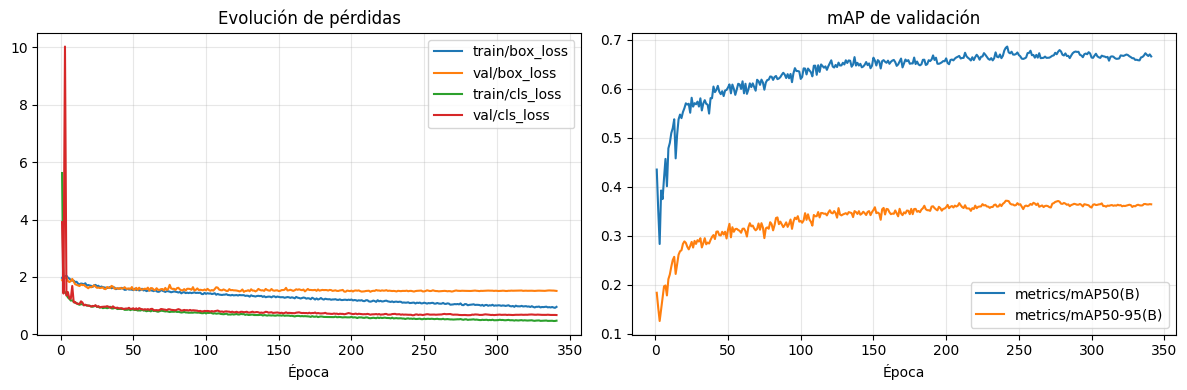

Épocas registradas: 341 | Mejor época de validación: 241


In [37]:
if VER_ENTRENAMIENTO:
    import matplotlib.pyplot as plt

    ruta = Path(pesos_matriculas).parent.parent / "results.csv"
    with ruta.open(newline="", encoding="utf-8-sig") as f:
        entrenamiento = [{k.strip(): v for k, v in fila.items()} for fila in csv.DictReader(f)]
    epocas = [int(f["epoch"]) for f in entrenamiento]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for clave in ["train/box_loss", "val/box_loss", "train/cls_loss", "val/cls_loss"]:
        ax[0].plot(epocas, [float(f[clave]) for f in entrenamiento], label=clave)
    for clave in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
        ax[1].plot(epocas, [float(f[clave]) for f in entrenamiento], label=clave)
    ax[0].set_title("Evolución de pérdidas")
    ax[1].set_title("mAP de validación")
    for eje in ax:
        eje.set_xlabel("Época")
        eje.grid(alpha=0.3)
        eje.legend()
    fig.tight_layout()
    carpeta_salida.mkdir(parents=True, exist_ok=True)
    fig.savefig(carpeta_salida / "entrenamiento.png", dpi=150)
    plt.show()
    mejor = max(entrenamiento, key=lambda f: float(f["metrics/mAP50-95(B)"]))
    print("Épocas registradas:", len(entrenamiento), "| Mejor época de validación:", mejor["epoch"])
else:
    print("Gráficas de entrenamiento desactivadas.")


## Referencias
- Material de la práctica: `README.md`, `VC_P4.ipynb` y `P4b/VC_P4b.ipynb`.
- Ultralytics. *Tracking*. https://docs.ultralytics.com/modes/track/
- Ultralytics. *Callbacks*. https://docs.ultralytics.com/usage/callbacks/
- OpenCV. *Geometric Image Transformations*. https://docs.opencv.org/4.9.0/da/d54/group__imgproc__transform.html
- PaddleOCR. *Instalación*. https://paddlepaddle.github.io/PaddleOCR/main/en/quick_start.html
- PaddleOCR. *OCR Pipeline (API 3.x)*. https://paddlepaddle.github.io/PaddleOCR/main/en/version3.x/pipeline_usage/OCR.html
- PaddleOCR. *Text Recognition Module (API 3.x)*. https://paddlepaddle.github.io/PaddleOCR/main/en/version3.x/module_usage/text_recognition.html
- PaddlePaddle. *Install on Windows via PIP*. https://github.com/PaddlePaddle/docs/blob/develop/docs/install/pip/windows-pip_en.md
- Reglamento General de Vehículos, anexo XVIII: formato ordinario actual y siglas provinciales del sistema antiguo. https://www.boe.es/eli/es/rd/1998/12/23/2822 y texto original: https://boe.es/buscar/doc.php?id=BOE-A-1999-1826

---

## PRACTICA 4b: Evaluación OCR - PaddleOCR vs SmolVLM

- En esta sección de la práctica, evaluaremos tanto el reconocedor clásico `en_PP-OCRv5_mobile_rec` como `HuggingFaceTB/SmolVLM-256M-Instruct` sobre los mismos recortes anotados de **test**. La implementación está en `comparativa_ocr.py`.

- Se mide exactitud de matrícula completa y latencia por matrícula con calentamiento, repeticiones y sincronización CUDA.

- Se usa la misma normalización alfanumérica para ambos motores. Se generan `images/comparativa_ocr/acierto.png` y `images/comparativa_ocr/tiempos.png` que se incluyen en el README. Con `SOLO_GRAFICAS_COMPARATIVA = True` se reutilizan las mediciones guardadas sin volver a ejecutar los modelos.

### Dependencias:

- La primera ejecución requiere acceso a `Hugging Face` para descargar SmolVLM si no existe en `models/SmolVLM-256M-Instruct`.

- En la siguiente sección de código podemos configurar ciertos parámetros para evaluar los modelos de OCR.

In [38]:
from pathlib import Path
import os
import sys
import subprocess

EJECUTAR_COMPARATIVA = False  # Activar para ejecutar esta sección.
SOLO_GRAFICAS_COMPARATIVA = False  # False: volver a medir ambos motores.
LIMITE_COMPARATIVA = 0  # Todas las matrículas legibles seleccionadas manualmente.
REPETICIONES_COMPARATIVA = 3
CALENTAMIENTO_COMPARATIVA = 3
SEMILLA_COMPARATIVA = 42
DISPOSITIVO_COMPARATIVA = "gpu"  # Ambos motores en GPU; alternativa: "cpu".
SALIDA_COMPARATIVA = Path("reports/comparativa_ocr")
MODELO_COMPARATIVA = (
    str(Path("models/SmolVLM-256M-Instruct").resolve())
    if Path("models/SmolVLM-256M-Instruct/config.json").is_file()
    else "HuggingFaceTB/SmolVLM-256M-Instruct"
)

SELECCION_COMPARATIVA = Path("reports/ocr_legibles/muestra.json")


- Con el siguiente código ejecutamos el programa `comparativa_ocr.py` con los diferentes argumentos configurados anteriormente para iniciar una nueva evaluación de ambos modelos de OCR, si `EJECUTAR_COMPARATIVA` es True.

In [39]:
if EJECUTAR_COMPARATIVA:
    comando = [
        sys.executable, "comparativa_ocr.py",
        "--seleccion", str(SELECCION_COMPARATIVA.resolve()),
        "--salida", str(SALIDA_COMPARATIVA.resolve()),
        "--modelo", MODELO_COMPARATIVA,
        "--limite", str(LIMITE_COMPARATIVA),
        "--semilla", str(SEMILLA_COMPARATIVA),
        "--repeticiones", str(REPETICIONES_COMPARATIVA),
        "--calentamiento", str(CALENTAMIENTO_COMPARATIVA),
        "--dispositivo", DISPOSITIVO_COMPARATIVA,
    ]
    if SOLO_GRAFICAS_COMPARATIVA:
        comando.append("--solo-graficas")
    # Mostrar progreso sin acumular la salida de los procesos en memoria.
    proceso = subprocess.Popen(comando, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, encoding="utf-8", errors="replace",
                               env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    try:
        for linea in proceso.stdout:
            print(linea, end="", flush=True)
        if proceso.wait() != 0:
            raise RuntimeError("La comparativa falló. Revisar el error anterior; las gráficas no se regeneraron.")
    except KeyboardInterrupt:
        # Windows: terminar también el motor hijo para no dejar inferencias activas.
        if sys.platform == "win32":
            subprocess.run(["taskkill", "/PID", str(proceso.pid), "/T", "/F"], capture_output=True)
        else:
            proceso.terminate()
        proceso.wait()
        raise
else:
    print("Comparativa desactivada. Activar EJECUTAR_COMPARATIVA para generar las gráficas.")


Comparativa desactivada. Activar EJECUTAR_COMPARATIVA para generar las gráficas.


Este código muestra los resultados guardados de la comparativa OCR:
- Lee `metricas.csv` y presenta la tasa de acierto y el tiempo medio de cada modelo.
- Muestra las gráficas `acierto.png` y `tiempos.png`.
- Añade un enlace al README de la comparativa.

PaddleOCR: 55.00% de acierto, media 18.49 ms
SmolVLM-256M: 47.00% de acierto, media 1178.08 ms


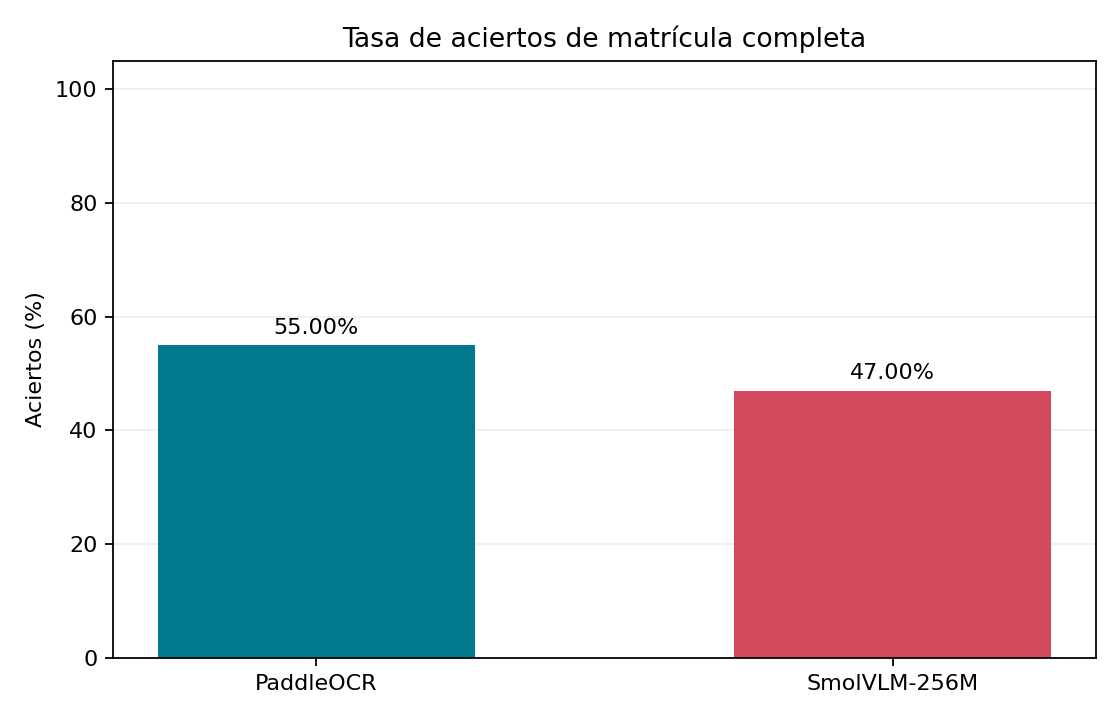

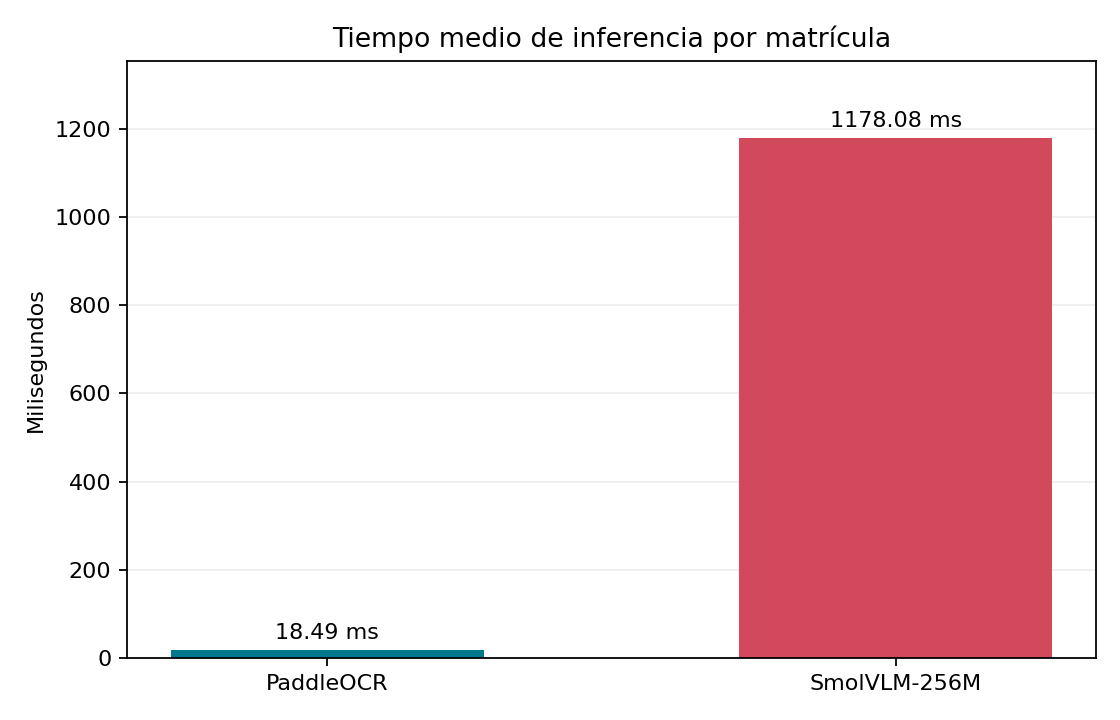

Informe: [README-COMPARATIVA-OCR.md](README-COMPARATIVA-OCR.md). Se muestran los últimos resultados guardados.

In [40]:
import csv
from IPython.display import display, Markdown, Image

ruta_metricas = SALIDA_COMPARATIVA / "metricas.csv"
if ruta_metricas.exists():
    with ruta_metricas.open(encoding="utf-8-sig", newline="") as f:
        metricas_comparativa = list(csv.DictReader(f))
    for fila in metricas_comparativa:
        print(f"{fila['motor']}: {float(fila['exactitud']):.2%} de acierto, "
              f"media {float(fila['media_ms']):.2f} ms")
    for nombre in ("acierto.png", "tiempos.png"):
        display(Image(filename=str(SALIDA_COMPARATIVA / nombre)))
    display(Markdown("Informe: [README-COMPARATIVA-OCR.md](README-COMPARATIVA-OCR.md). "
                     "Se muestran los últimos resultados guardados."))
else:
    print("Todavía no hay resultados medidos. Ejecutar la celda de comparativa.")
